#**TP 3 - ESTATÍSTICA APLICADA E ANÁLISE EXPLORATÓRIA DE DADOS**

#CÓDIGO PARA GERAÇÃO DOS DATASETS

In [1]:
import numpy as np
import pandas as pd
import json
from datetime import datetime, timedelta

In [2]:
rng = np.random.default_rng(42)
n = 4000
start_date = datetime(2026, 1, 5)

ticket_ids = [f"TCK-{i:05d}" for i in range(1, n + 1)]
cliente_ids = [f"CLI-{i:03d}" for i in rng.integers(1, 181, n)]
dias_offset = np.sort(rng.integers(0, 180, n))
datas = [(start_date + timedelta(days=int(d))).strftime("%Y-%m-%d") for d in dias_offset]
canais = rng.choice(["email", "chat", "telefone"], size=n, p=[0.45, 0.35, 0.20])
categorias = rng.choice(["bug", "duvida_de_uso", "cobranca", "elogio"], size=n, p=[0.35, 0.30, 0.25, 0.10])
prioridades = rng.choice(["baixa", "media", "alta", "critica"], size=n, p=[0.30, 0.35, 0.25, 0.10])
tempo_resposta = np.clip(rng.gamma(shape=2.0, scale=2.2, size=n), 0.2, 48)
tempo_resposta[canais == "chat"] *= 0.6
tempo_resolucao = np.clip(1.8 * tempo_resposta + 3 + rng.normal(0, 1.5, n), 0.5, 120)
satisfacao = 5 - (tempo_resposta / 6) + rng.normal(0, 0.6, n)
satisfacao[canais == "chat"] -= 0.6
satisfacao = np.clip(np.round(satisfacao), 1, 5)

df = pd.DataFrame({
    "ticket_id": ticket_ids,
    "cliente_id": cliente_ids,
    "data_abertura": datas,
    "canal": canais,
    "categoria": categorias,
    "prioridade": prioridades,
    "tempo_resposta_horas": tempo_resposta,
    "tempo_resolucao_horas": tempo_resolucao,
    "satisfacao_cliente": satisfacao,
})

# valores ausentes (como em uma exportacao real)
df.loc[rng.choice(n, size=int(n * 0.08), replace=False), "tempo_resposta_horas"] = np.nan
df.loc[rng.choice(n, size=int(n * 0.10), replace=False), "satisfacao_cliente"] = np.nan

# tempo_resposta_horas exportado como texto, com virgula decimal
def fmt_virgula(v):
    return "" if pd.isna(v) else f"{v:.2f}".replace(".", ",")

df["tempo_resposta_horas"] = df["tempo_resposta_horas"].apply(fmt_virgula)

# duplicatas de reenvio, anexadas ao final
duplicatas = df.sample(frac=0.02, random_state=42)
df_final = pd.concat([df, duplicatas], ignore_index=True)
df_final.to_csv("tickets_suporte.csv", index=False)

In [3]:
clientes_unicos = sorted(set(cliente_ids))
planos = pd.DataFrame({
    "cliente_id": clientes_unicos,
    "valor_plano": rng.choice([99.0, 199.0, 349.0, 599.0], size=len(clientes_unicos), p=[0.4, 0.3, 0.2, 0.1]),
    "segmento": rng.choice(["starter", "growth", "enterprise"], size=len(clientes_unicos), p=[0.5, 0.35, 0.15]),
})
planos.to_excel("planos_clientes.xlsx", index=False)

In [4]:
chat_ids = df.loc[df["canal"] == "chat", "ticket_id"].tolist()
triagem = [
    {
        "ticket_id": tid,
        "intencao_triagem": str(rng.choice(["duvida", "reclamacao", "solicitacao", "elogio"])),
        "confianca_bot": round(float(rng.uniform(0.55, 0.98)), 2),
    }
    for tid in chat_ids
]

with open("chatbot_triagem.json", "w", encoding="utf-8") as f:
    json.dump(triagem, f, ensure_ascii=False, indent=2)

#TP 3

## Modelo de LLM utilizado

Todos os prompts registrados neste notebook foram enviados ao **Claude Opus 5**, da Anthropic, acessado pela interface de chat. Nenhum outro modelo foi consultado.

Os Exercícios 1 a 7 foram conduzidos em uma única conversa, o que faz com que o modelo tenha contexto acumulado dos prompts anteriores. O Exercício 8 foi iniciado em uma conversa nova, para evitar influência do contexto do chat.


## Organização das duas versões da base

Este TP refaz, com apoio de um LLM, etapas de limpeza que já foram feitas manualmente no TP1. Para poder comparar as duas abordagens, o notebook carrega a base em duas versões:

**v1** -> o pipeline manual do TP1, reproduzido integralmente. Serve como gabarito de comparação e não é usado nas análises.

**v2** -> os três arquivos brutos, sem nenhum tratamento. É sobre esta versão que o código gerado pelo LLM é executado, e dela nasce o `df_consolidado_v2` usado dos Exercícios 3 a 8.

## Carga, limpeza e preparação dos dados - versão v1 (pipeline manual do TP1)

In [5]:
df_tickets_v1 = pd.read_csv("tickets_suporte.csv")
df_planos_v1 = pd.read_excel("planos_clientes.xlsx")
df_triagem_v1 = pd.read_json("chatbot_triagem.json")

df_tickets_v1["data_abertura"] = df_tickets_v1["data_abertura"].astype("datetime64[ns]")
df_tickets_v1["tempo_resposta_horas"] = (
    df_tickets_v1["tempo_resposta_horas"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

mediana_por_categoria_v1 = df_tickets_v1.groupby("categoria")["tempo_resposta_horas"].transform("median")
df_tickets_v1["tempo_resposta_horas"] = df_tickets_v1["tempo_resposta_horas"].fillna(mediana_por_categoria_v1)
df_tickets_v1 = df_tickets_v1.dropna(subset=["ticket_id"])
df_tickets_v1 = df_tickets_v1.drop_duplicates(subset=["ticket_id"], keep="first")

df_consolidado_v1 = pd.merge(df_tickets_v1, df_planos_v1, on="cliente_id", how="left")
df_consolidado_v1 = pd.merge(df_consolidado_v1, df_triagem_v1, on="ticket_id", how="left")

print("shape final v1:")
print(df_consolidado_v1.shape)

shape final v1:
(4000, 13)


## Carga dos arquivos sem tratamento - versão v2 (base para o trabalho com LLM)

In [6]:
df_tickets_v2 = pd.read_csv("tickets_suporte.csv")
df_planos_v2 = pd.read_excel("planos_clientes.xlsx")
df_triagem_v2 = pd.read_json("chatbot_triagem.json")

print("shape:")
print(df_tickets_v2.shape)

print("\ndtypes:")
print(df_tickets_v2.dtypes)

print("\nnulos por coluna:")
print(df_tickets_v2.isna().sum())

shape:
(4080, 9)

dtypes:
ticket_id                 object
cliente_id                object
data_abertura             object
canal                     object
categoria                 object
prioridade                object
tempo_resposta_horas      object
tempo_resolucao_horas    float64
satisfacao_cliente       float64
dtype: object

nulos por coluna:
ticket_id                  0
cliente_id                 0
data_abertura              0
canal                      0
categoria                  0
prioridade                 0
tempo_resposta_horas     329
tempo_resolucao_horas      0
satisfacao_cliente       407
dtype: int64


## Imports

In [7]:
import numpy as np
import pandas as pd
import json
from scipy import stats
from scipy.stats import bootstrap
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns
import statsmodels.formula.api as smf

#TP3 - Respostas

##**EXERCÍCIO 1**

### 1.1 Escreva um prompt para um LLM pedindo código pandas que trate valores ausentes em tempo_resposta_horas e remova duplicatas em ticket_id, incluindo no prompt o nome exato das colunas e o critério de negócio (ex.: preencher com a mediana por categoria).

**PROMPT ENVIADO À LLM**

```
Estou trabalhando com pandas em um notebook Jupyter, em uma base de tickets de suporte de uma empresa de software (CloudDesk). Tenho um DataFrame chamado df_tickets_v2, carregado diretamente do arquivo tickets_suporte.csv com pd read_csv, sem nenhum tratamento aplicado.

As colunas do DataFrame são exatamente estas: ticket_id, cliente_id, data_abertura, canal, categoria, prioridade, tempo_resposta_horas, tempo_resolucao_horas, satisfacao_cliente.

Contexto de negócio:
- ticket_id é a chave primária do chamado e não pode se repetir. O sistema de exportação reenvia alguns chamados, então existem linhas duplicadas anexadas ao fim do arquivo.
- categoria assume os valores bug, duvida_de_uso, cobranca e elogio.
- tempo_resposta_horas é o tempo até a primeira resposta do time de suporte e tem valores ausentes na exportação.

Preciso de código pandas que:
1. Preencha os valores ausentes de tempo_resposta_horas com a mediana da própria categoria do ticket (mediana por categoria, não a mediana global), porque a distribuição desse tempo tem cauda longa à direita e a média seria puxada pelos extremos.
2. Remova as duplicatas usando ticket_id como critério de duplicidade, mantendo o primeiro registro de cada ticket.
3. Imprima, ao final, o número de linhas antes e depois, e a contagem de valores ausentes restantes em tempo_resposta_horas.

Gere apenas o código pandas, comentado, sem executar e sem inventar as saídas.
```

### 1.2 Cole a resposta do LLM no notebook, junto com o prompt utilizado.

**RESPOSTA DA LLM**

> Um ponto antes do código: como o CSV foi lido sem tratamento, `tempo_resposta_horas` chega como texto com vírgula decimal. Sem converter para numérico primeiro, o `groupby(...).median()` falha (ou, pior, se algum caminho silencioso passar, devolve resultado sem sentido). A conversão vem antes de tudo.
>
> A outra decisão é a ordem: removo as duplicatas antes de calcular a mediana. Se preencher primeiro, os ~80 chamados reenviados entram duas vezes no cálculo e distorcem levemente a mediana por categoria.
>
> *[código gerado - colado na célula abaixo]*
>
> Duas observações sobre o resultado:
>
> O contador de ausentes só chega a zero se toda categoria tiver pelo menos um valor válido. Nesta base isso acontece, mas se uma categoria viesse inteira em branco, o `transform` devolveria NaN e o `fillna` não teria com que preencher — por isso vale imprimir a contagem em vez de assumir.
>
> E o preenchimento por mediana de categoria ignora o canal, que é o fator que mais mexe nesse tempo (chat responde bem mais rápido que e-mail e telefone). Se o tempo preenchido for entrar em alguma análise por canal depois, considere `groupby(["categoria", "canal"])` para não achatar essa diferença.

**CÓDIGO GERADO PELA LLM**



In [8]:
# --- 0) Copia de trabalho, para nao alterar o df original carregado -------------
df = df_tickets_v2.copy()

# --- 1) Conversao do tempo de resposta para numerico ---------------------------
# A coluna vem da exportacao como texto com virgula decimal ("1,54").
# Troca virgula por ponto e converte; strings vazias viram NaN (errors="coerce").
df["tempo_resposta_horas"] = pd.to_numeric(
    df["tempo_resposta_horas"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)

# Contagem de linhas ANTES da remocao de duplicatas
linhas_antes = len(df)

# --- 2) Remocao das duplicatas de reenvio --------------------------------------
# ticket_id e a chave primaria: mantem a primeira ocorrencia de cada chamado.
# Feito ANTES do preenchimento para que os reenvios nao pesem na mediana.
df = df.drop_duplicates(subset="ticket_id", keep="first").reset_index(drop=True)

linhas_depois = len(df)

# --- 3) Preenchimento dos ausentes pela mediana da propria categoria ------------
# A mediana e robusta a cauda longa a direita do tempo de resposta;
# transform("median") devolve a mediana da categoria alinhada a cada linha.
mediana_por_categoria = df.groupby("categoria")["tempo_resposta_horas"].transform("median")
df["tempo_resposta_horas"] = df["tempo_resposta_horas"].fillna(mediana_por_categoria)

# --- 4) Relatorio final ---------------------------------------------------------
print(f"Linhas antes da remocao de duplicatas:  {linhas_antes}")
print(f"Linhas depois da remocao de duplicatas: {linhas_depois}")
print(f"Duplicatas removidas:                   {linhas_antes - linhas_depois}")
print(f"Ausentes restantes em tempo_resposta_horas: {df['tempo_resposta_horas'].isna().sum()}")

df_tickets_llm = df

Linhas antes da remocao de duplicatas:  4080
Linhas depois da remocao de duplicatas: 4000
Duplicatas removidas:                   80
Ausentes restantes em tempo_resposta_horas: 0


### 1.3 Execute o código gerado sobre a base de tickets e confirme se o resultado é equivalente ao obtido manualmente no TP1.

In [26]:
print("shape LLM:", df_tickets_llm.shape, "| shape v1:", df_tickets_v1.shape)

serie_llm = df_tickets_llm.set_index("ticket_id")["tempo_resposta_horas"].sort_index()
serie_v1 = df_tickets_v1.set_index("ticket_id")["tempo_resposta_horas"].sort_index()

print("\nMesmos ticket_id nos dois DataFrames?")
print(serie_llm.index.equals(serie_v1.index))

diferenca = (serie_llm - serie_v1).abs()
print("\nLinhas divergentes em tempo_resposta_horas:")
print((diferenca > 1e-9).sum())
print("\nDiferença maxima:")
print(round(diferenca.max(), 4))
print("\nMédia tempo_resposta_horas - LLM:", round(df_tickets_llm["tempo_resposta_horas"].mean(), 6))
print("Média tempo_resposta_horas - v1 :", round(df_tickets_v1["tempo_resposta_horas"].mean(), 6))

shape LLM: (4000, 9) | shape v1: (4000, 9)

Mesmos ticket_id nos dois DataFrames?
True

Linhas divergentes em tempo_resposta_horas:
236

Diferença maxima:
0.045

Média tempo_resposta_horas - LLM: 3.811945
Média tempo_resposta_horas - v1 : 3.81083


**MINHA ANÁLISE**

O código gerado pela LLM roda sem erro e chega ao mesmo número de linhas do TP1: 4080 linhas de entrada, 80 duplicatas removidas, 4000 tickets únicos e zero ausentes restantes em `tempo_resposta_horas`. Pelo `shape` e pela contagem de nulos, o resultado parece idêntico.

Comparando linha a linha, porém, 236 dos 4000 tickets têm valor diferente em `tempo_resposta_horas`, com diferença máxima de 0,045 hora e média de 3,811945 contra 3,810830 do TP1. O resultado é equivalente em estrutura, mas não em conteúdo, e nenhuma das verificações agregadas usuais teria revelado isso.

A causa é a ordem das operações, no TP1 o preenchimento foi feito antes da remoção de duplicatas, e o modelo inverteu essa ordem.

##**EXERCÍCIO 2**

### 2.1 Liste três aspectos do código gerado no Exercício 1 que precisam ser verificados manualmente antes de confiar no resultado.

**Primeiro aspecto - a estratégia de preenchimento é realmente a mediana por categoria?** O modelo poderia ter usado a mediana global e o resultado continuaria plausível. É preciso conferir se o `groupby("categoria").transform("median")` alinha de fato a mediana da própria categoria a cada linha, e não um valor único para toda a base.

**Segundo aspecto - a ordem entre a remoção de duplicatas e o preenchimento.** O prompt não especificou essa ordem e o modelo decidiu sozinho, invertendo o que foi realizado no TP1. Como as duplicatas entram no cálculo da mediana quando o preenchimento vem primeiro, é preciso verificar se elas estão distribuídas de forma proporcional entre as categorias ou se concentram em algumas delas.

**Terceiro aspecto - o `errors="coerce"` na conversão numérica.** O parâmetro transforma qualquer texto não conversível em `NaN` sem levantar exceção, e o `fillna` logo em seguida substitui esse `NaN` pela mediana da categoria. Um valor corrompido é convertido em um número plausível sem deixar rastro, e o contador de nulos ao final chega a zero da mesma forma que chegaria se o dado estivesse íntegro.

### 2.2 Identifique, se houver, algum erro, suposição incorreta ou comportamento inesperado no código gerado, testando-o sobre um subconjunto conhecido dos dados.

**Teste 1: as duplicatas estão distribuídas proporcionalmente entre as categorias?**

In [10]:
raw = pd.read_csv("tickets_suporte.csv")
tempo_numerico = pd.to_numeric(
    raw["tempo_resposta_horas"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
raw_num = raw.assign(tempo=tempo_numerico)
sem_duplicatas = raw_num.drop_duplicates(subset="ticket_id", keep="first")
linhas_duplicadas = raw_num[raw_num["ticket_id"].duplicated(keep="first")]

comparacao = pd.DataFrame({
    "pct_na_base": (sem_duplicatas.groupby("categoria").size() / len(sem_duplicatas) * 100).round(2),
    "pct_nas_duplicatas": (linhas_duplicadas.groupby("categoria").size() / len(linhas_duplicadas) * 100).round(2),
    "mediana_TP1_com_duplicatas": raw_num.groupby("categoria")["tempo"].median(),
    "mediana_LLM_sem_duplicatas": sem_duplicatas.groupby("categoria")["tempo"].median(),
})
comparacao["diferenca_mediana"] = (
    comparacao["mediana_LLM_sem_duplicatas"] - comparacao["mediana_TP1_com_duplicatas"]
).round(4)
comparacao["nulos_a_preencher"] = sem_duplicatas[sem_duplicatas["tempo"].isna()].groupby("categoria").size()
comparacao["linhas_afetadas"] = np.where(
    comparacao["diferenca_mediana"] != 0, comparacao["nulos_a_preencher"], 0
)

print(comparacao.to_string())
print("\nTotal de linhas afetadas pela mudanca de ordem:")
print(comparacao["linhas_afetadas"].sum())

               pct_na_base  pct_nas_duplicatas  mediana_TP1_com_duplicatas  mediana_LLM_sem_duplicatas  diferenca_mediana  nulos_a_preencher  linhas_afetadas
categoria                                                                                                                                                    
bug                  34.67               38.75                       3.120                        3.13              0.010                112              112
cobranca             25.70               18.75                       3.210                        3.21              0.000                 84                0
duvida_de_uso        29.80               32.50                       3.025                        3.07              0.045                 92               92
elogio                9.83               10.00                       3.125                        3.10             -0.025                 32               32

Total de linhas afetadas pela mudanca de ordem:
236

As 80 duplicatas não reproduzem a composição da base: `bug` responde por 38,75% delas contra 34,67% do total, e `cobranca` por 18,75% contra 25,70%. Como a mediana é sensível a essa recontagem desigual, três das quatro categorias mudam de valor imputado, e as 236 linhas divergentes são exatamente as linhas nulas dessas três categorias.

Não é um erro da LLM, a justificativa dada, reenvio de exportação não deveria pesar duas vezes no cálculo de uma estatística, faz mais sentido que a ordem adotada no TP1. O comportamento inesperado é que uma decisão não solicitada, tomada silenciosamente pelo modelo, alterou 236 registros sem aparecer em nenhuma verificação de `shape`, `dtypes` ou contagem de nulos.

**Teste 2: o que acontece com um valor corrompido, sobre um subconjunto conhecido**

In [27]:
subconjunto = sem_duplicatas.loc[
    sem_duplicatas["categoria"] == "bug", ["ticket_id", "categoria", "tempo_resposta_horas"]
].head(5).copy()

print("Subconjunto original:")
print(subconjunto.to_string(index=False))

subconjunto.loc[subconjunto.index[1], "tempo_resposta_horas"] = "3;45"

teste = subconjunto.copy()
teste["tempo_resposta_horas"] = pd.to_numeric(
    teste["tempo_resposta_horas"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
print("\nApós to_numeric(errors='coerce'):")
print(teste.to_string(index=False))

teste["tempo_resposta_horas"] = teste["tempo_resposta_horas"].fillna(
    teste.groupby("categoria")["tempo_resposta_horas"].transform("median")
)
print("\nApós fillna pela mediana da categoria:")
print(teste.to_string(index=False))

Subconjunto original:
ticket_id categoria tempo_resposta_horas
TCK-00003       bug                 2,04
TCK-00004       bug                 5,19
TCK-00015       bug                 0,63
TCK-00016       bug                 2,05
TCK-00019       bug                 1,70

Após to_numeric(errors='coerce'):
ticket_id categoria  tempo_resposta_horas
TCK-00003       bug                  2.04
TCK-00004       bug                   NaN
TCK-00015       bug                  0.63
TCK-00016       bug                  2.05
TCK-00019       bug                  1.70

Após fillna pela mediana da categoria:
ticket_id categoria  tempo_resposta_horas
TCK-00003       bug                  2.04
TCK-00004       bug                  1.87
TCK-00015       bug                  0.63
TCK-00016       bug                  2.05
TCK-00019       bug                  1.70


O ticket TCK-00004 tinha valor real de 5,19 horas. Com um único caractere corrompido, o `errors="coerce"` o transformou em `NaN` e o `fillna` o substituiu por 1,87 hora, a mediana do subconjunto, um erro de 64% no valor, sem exceção, sem aviso e sem nenhuma marca no DataFrame que permitisse encontrá-lo depois.

Na base atual isso não chega a acontecer, porque a contagem de conversões que falharam sem ser célula vazia é zero. Mas o código não distingue os dois casos, e é essa distinção que a versão corrigida acrescenta.

### 2.3 Corrija o código, se necessário, e registre no notebook a diferença entre a versão gerada pelo LLM e a versão corrigida por você.

In [28]:
df_v2 = df_tickets_v2.copy()

# Correção 1: separa célula vazia de valor corrompido antes de deixar o coerce agir
texto_tempo = df_v2["tempo_resposta_horas"].astype(str).str.replace(",", ".", regex=False)
df_v2["tempo_resposta_horas"] = pd.to_numeric(texto_tempo, errors="coerce")

era_vazio = df_tickets_v2["tempo_resposta_horas"].isna() | (texto_tempo.str.strip() == "")
falha_conversao = df_v2["tempo_resposta_horas"].isna() & ~era_vazio
print("Valores que falharam na conversão e nao eram vazios:")
print(falha_conversao.sum())

# Correção 2: conversão de data_abertura, ausente no código gerado
df_v2["data_abertura"] = pd.to_datetime(df_v2["data_abertura"])

# Correção 3: dropna na chave primária, ausente no código gerado
linhas_antes_v2 = len(df_v2)
df_v2 = df_v2.dropna(subset=["ticket_id"])
df_v2 = df_v2.drop_duplicates(subset="ticket_id", keep="first").reset_index(drop=True)
linhas_depois_v2 = len(df_v2)

# Mantida a ordem escolhida pela LLM, dedup antes do preenchimento
mediana_por_categoria_v2 = df_v2.groupby("categoria")["tempo_resposta_horas"].transform("median")
df_v2["tempo_resposta_horas"] = df_v2["tempo_resposta_horas"].fillna(mediana_por_categoria_v2)

print("\nLinhas antes:", linhas_antes_v2, "| depois:", linhas_depois_v2, "| removidas:", linhas_antes_v2 - linhas_depois_v2)
print("Ausentes restantes em tempo_resposta_horas:", df_v2["tempo_resposta_horas"].isna().sum())

# Correção 4: os merges, ausentes no código gerado
df_consolidado_v2 = pd.merge(df_v2, df_planos_v2, on="cliente_id", how="left")
df_consolidado_v2 = pd.merge(df_consolidado_v2, df_triagem_v2, on="ticket_id", how="left")

print("\nshape final v2:")
print(df_consolidado_v2.shape)

Valores que falharam na conversão e nao eram vazios:
0

Linhas antes: 4080 | depois: 4000 | removidas: 80
Ausentes restantes em tempo_resposta_horas: 0

shape final v2:
(4000, 13)


In [29]:
print("shape v2:", df_consolidado_v2.shape, "| shape v1:", df_consolidado_v1.shape)
print("\nMesmas colunas?")
print(list(df_consolidado_v2.columns) == list(df_consolidado_v1.columns))
print("\nMesmos ticket_id?")
print(set(df_consolidado_v2["ticket_id"]) == set(df_consolidado_v1["ticket_id"]))

comparacao_final = df_consolidado_v2[["ticket_id", "tempo_resposta_horas"]].merge(
    df_consolidado_v1[["ticket_id", "tempo_resposta_horas"]],
    on="ticket_id", suffixes=("_v2", "_v1"),
)
delta = (comparacao_final["tempo_resposta_horas_v2"] - comparacao_final["tempo_resposta_horas_v1"]).abs()

print("\nLinhas divergentes:", (delta > 1e-9).sum())
print("Diferença máxima:", round(delta.max(), 4))
print("Média v2:", round(df_consolidado_v2["tempo_resposta_horas"].mean(), 4), "| média v1:", round(df_consolidado_v1["tempo_resposta_horas"].mean(), 4))
print("\ndtype de data_abertura em v2:", df_consolidado_v2["data_abertura"].dtype)

shape v2: (4000, 13) | shape v1: (4000, 13)

Mesmas colunas?
True

Mesmos ticket_id?
True

Linhas divergentes: 236
Diferença máxima: 0.045
Média v2: 3.8119 | média v1: 3.8108

dtype de data_abertura em v2: datetime64[ns]


**Diferença entre a versão gerada pelo LLM e a versão corrigida**

A ordem de operações foi mantida como o modelo propôs, porque a justificativa dele é melhor do que a realizada anteriormente. A divergência de 236 linhas em relação ao `df_consolidado_v1` permanece, e fica registrada como escolha consciente, não como erro.

Quatro correções foram acrescentadas. A primeira separa célula vazia de valor corrompido antes que o `errors="coerce"` apague a distinção, e imprime a contagem. A segunda converte `data_abertura` para `datetime`, que o código gerado não fazia. A terceira aplica `dropna` na chave primária, e a quarta faz os dois merges com planos e triagem, montando o `df_consolidado_v2`.

Três das quatro correções são de escopo, não de lógica, já que o prompt pediu apenas o tratamento de nulos e duplicatas. O código gerado estava certo para o que foi pedido, porém incompleto para o que vai ser necessário.

##**EXERCÍCIO 3**

### 3.1 Use um LLM para gerar uma lista de perguntas analíticas candidatas sobre os fatores associados à satisfação do cliente, fornecendo como contexto as colunas disponíveis no dataset de tickets.

**PROMPT ENVIADO À LLM**

```
Sou engenheiro de dados na CloudDesk, uma empresa de software com um time de suporte. Preciso investigar quais fatores estão associados à satisfação do cliente com o atendimento.

O DataFrame consolidado que tenho disponível tem estas colunas:
- ticket_id: identificador do chamado
- cliente_id: identificador do cliente
- data_abertura: data de abertura do chamado
- canal: email, chat ou telefone
- categoria: bug, duvida_de_uso, cobranca ou elogio
- prioridade: baixa, media, alta ou critica
- tempo_resposta_horas: horas até a primeira resposta
- tempo_resolucao_horas: horas até a resolução do chamado
- satisfacao_cliente: nota de 1 a 5 dada pelo cliente (com valores ausentes)
- valor_plano: valor mensal do plano do cliente
- segmento: starter, growth ou enterprise
- intencao_triagem: intenção detectada pelo chatbot (só para tickets do canal chat)
- confianca_bot: confiança do chatbot na triagem (só para tickets do canal chat)

Gere de 8 a 12 perguntas analíticas candidatas sobre os fatores associados à satisfação do cliente. Não se limite ao que é respondível com as colunas acima: inclua também perguntas que você considere relevantes para o problema de negócio mesmo que exijam dados que eu não listei, e marque quais são essas. Apenas as perguntas, sem código.
```

**RESPOSTA DA LLM**

> Onze perguntas, agrupadas pelo que a base atual suporta e pelo que exigiria dados adicionais.
>
> **Respondíveis com as colunas que você tem**
>
> **1. Qual o peso relativo do tempo de resposta versus o tempo de resolução na nota?**
> Os dois são altamente correlacionados entre si, então a pergunta real é qual deles o cliente de fato "sente". Se a primeira resposta explica quase tudo e a resolução acrescenta pouco, a alavanca operacional é acknowledgment rápido, não fechamento rápido.
>
> **2. A relação entre tempo e satisfação é linear ou tem um ponto de quebra?**
> Interessa saber se existe um limiar (2h? 4h?) a partir do qual a nota despenca, em vez de cair de forma suave. Isso é o que vira SLA defensável.
>
> **3. O canal chat tem penalidade de satisfação própria, independente do tempo?**
> Já dá para ver na base que o chat responde mais rápido e mesmo assim pontua abaixo dos outros canais em todas as faixas de tempo. Vale quantificar esse efeito residual e checar se ele é estável por categoria e por segmento.
>
> **4. Como a satisfação varia por categoria, e o quanto disso é confundido pelo tipo de problema?**
> Um chamado de cobranca pode ter nota baixa pelo assunto em si, não pelo atendimento. Separar "insatisfação com o produto/cobrança" de "insatisfação com o suporte" muda completamente a leitura.
>
> **5. Prioridade alta/crítica está sendo atendida proporcionalmente mais rápido — e isso se converte em nota?**
> Testa se a política de priorização funciona e se o cliente percebe. Um ticket crítico atendido no mesmo tempo de um baixo é uma falha de processo visível na nota.
>
> **6. Segmento e valor de plano preveem satisfação depois de controlar pelo tempo de atendimento?**
> Se o enterprise pontua mais alto só porque é atendido mais rápido, é efeito de serviço. Se pontua mais alto com o mesmo tempo, é expectativa/tolerância diferente — e a implicação para o negócio é oposta.
>
> **7. Existe efeito de acumulação por cliente?**
> A nota do cliente cai conforme o número de chamados que ele abriu no período, ou depois de uma experiência ruim anterior? Isso testa satisfação como histórico, não como evento isolado, e é o que mais se aproxima de risco de churn.
>
> **8. Os ausentes de satisfacao_cliente são aleatórios ou informativos?**
> Se quem não responde a pesquisa se concentra nos chamados demorados, a média observada está enviesada para cima e todas as conclusões acima estão otimistas demais. Essa pergunta precisa vir cedo, porque condiciona as outras.
>
> **9. Erro de triagem do chatbot degrada a nota?**
> Comparar intencao_triagem com categoria dá um proxy de acerto. Vale checar se a nota cai quando o bot erra, e se a confianca_bot alta e errada é pior que confiança baixa (falsa certeza roteia para o lugar errado sem escalar).
>
> **Exigem dados que você não listou**
>
> **10. Quantas transferências e reaberturas o chamado teve?** ⚠️
> Suspeito que seja o fator mais forte que está faltando. Ser passado entre três atendentes ou ter o ticket reaberto costuma pesar mais na nota que uma hora a mais de espera. Precisaria de contagem de handoffs, número de interações e flag de reabertura.
>
> **11. Quem atendeu, e em que condição de carga?** ⚠️
> Identificador do atendente, tempo de casa e fila/backlog no momento da abertura. Permite separar variação de pessoa e de sobrecarga do time daquilo que é característica do chamado — e responder se contratar mais gente melhora a nota mais do que treinar.
>
> **12. O problema foi de fato resolvido?** ⚠️
> Você tem tempo até a resolução, mas não o desfecho: resolvido, contornado ou encerrado por inatividade. Sem isso, "resolução rápida" pode estar capturando chamados fechados no grito, que é justamente onde a nota deve ser pior.
>
> Um comentário sobre a ordem: eu rodaria a 8 antes de tudo. Com 10% de não resposta concentrada em algum lugar, as perguntas 1 a 7 respondem sobre a população errada. Depois disso, a 1 e a 3 são as que produzem decisão operacional mais direta.

### 3.2 Selecione, entre as perguntas geradas, as três mais respondíveis com os dados disponíveis e justifique a escolha.

As três selecionadas são a 8, a 1 e a 3.

A pergunta 8, sobre a natureza dos valores ausentes de `satisfacao_cliente`, vem primeiro porque condiciona todas as outras. É respondível com o que existe na base: basta construir um indicador de ausência e cruzá-lo com as demais colunas. Se a ausência se concentrar nos chamados demorados, as médias calculadas por descarte listwise estarão enviesadas para cima e nenhuma das outras respostas se sustenta.

A pergunta 1, sobre o peso relativo dos dois tempos, é respondível porque as três variáveis envolvidas estão completas ou quase completas na base, e porque o TP2 já mostrou o problema que ela precisa resolver: as duas correlações com satisfação ficaram praticamente empatadas em −0,458 e −0,460, e as duas variáveis correlacionam 0,92 entre si. Separa investir em primeira resposta de investir em fechamento.

A pergunta 3, sobre a penalidade própria do canal chat, é respondível por estratificação: comparar canais dentro de faixas equivalentes de tempo de resposta usa apenas colunas existentes e n suficiente em todas as faixas.

### 3.3 Descarte explicitamente qualquer pergunta gerada que exigiria dados que a CloudDesk não possui, explicando por quê.

As perguntas 10, 11 e 12 são descartadas.

A 10 exigiria contagem de transferências entre atendentes, número de interações e flag de reabertura. A base tem uma linha por chamado e nenhuma coluna sobre o que aconteceu dentro dele, então não há como distinguir um ticket resolvido na primeira resposta de um que passou por três atendentes no mesmo intervalo de tempo.

A 11 exigiria identificador do atendente e alguma medida de carga da fila. A base não identifica quem atendeu, o que impede separar variação entre pessoas e efeito de sobrecarga daquilo que é característica do chamado.

A 12 é a mais grave das três, `tempo_resolucao_horas` mede quando o chamado foi fechado, não se o problema foi resolvido. Sem uma coluna de desfecho, um ticket encerrado por inatividade e um ticket efetivamente resolvido são indistinguíveis, e "resolução rápida" pode estar capturando justamente os chamados fechados no grito, onde a nota deveria ser pior.

##**EXERCÍCIO 4**

### 4.1 Para cada uma das três perguntas selecionadas no Exercício 3, peça ao LLM que gere o código pandas de análise descritiva correspondente.

### 4.2 Execute cada trecho de código gerado sobre a base de tickets e registre o resultado.

### 4.3 Para cada resultado, escreva uma frase de interpretação em linguagem de negócio.

### Pergunta 1 - os ausentes de satisfacao_cliente são aleatórios ou informativos?

**PROMPT ENVIADO À LLM**

```
[bloco de contexto com o schema do df_consolidado_v2, idêntico ao do Exercício 3]

Pergunta a responder: os valores ausentes de satisfacao_cliente são aleatórios ou informativos? Ou seja, a ausência de resposta à pesquisa se concentra em tickets com tempo de atendimento maior, em algum canal, categoria ou segmento específico?

Gere o código pandas de análise descritiva para responder isso: taxa de ausência por canal, categoria, prioridade e segmento, e comparação do tempo de resposta e de resolução médios entre tickets com e sem nota. Apenas código, sem inventar as saídas.
```

**RESPOSTA DA LLM**

> Boa pergunta para fazer antes das outras — se a ausência for informativa, todas as médias de satisfação calculadas até aqui estão enviesadas.
>
> Uma nota sobre leitura: o teste distingue MCAR de MAR (ausência ligada a variáveis observadas). Nenhuma análise dos dados consegue descartar MNAR — ausência ligada à própria nota não dada, que é o cenário mais perigoso. Voltarei a isso no fim.
>
> *[código gerado - colado na célula abaixo]*
>
> **Como interpretar**
>
> O pseudo R² da logística é o resumo mais direto. Se ficar praticamente em zero e nenhum coeficiente for relevante, a ausência é indistinguível de aleatória (MCAR) e você pode seguir com descarte listwise sem culpa.
>
> Se tempo_resposta_horas sair com coeficiente positivo e a tabela do bloco 3 mostrar taxa crescente do Q1 ao Q5, é MAR: a ausência depende de algo que você observa. Nesse caso o descarte listwise enviesa a satisfação média para cima, porque os atendimentos ruins somem da amostra — e a correção é ponderar por inverso da probabilidade de resposta (usando exatamente a logística acima) ou imputação múltipla.
>
> Atenção ao V de Cramér, não só ao p. Com n = 4.000, um qui-quadrado pode dar significativo com diferença de meio ponto percentual entre canais, o que é irrelevante na prática.
>
> **O limite deste diagnóstico**
>
> Nada aqui detecta MNAR — o caso em que o cliente muito insatisfeito não responde por estar insatisfeito, independentemente de tempo, canal ou segmento. Esse cenário produz exatamente os mesmos resultados de um MCAR nos testes acima, e só se resolve com dado externo: uma amostra de follow-up ativo com os não respondentes, ou taxa de churn cruzada com quem não deu nota. Se a decisão de negócio for sensível a isso, vale sugerir à liderança que o time de suporte faça esse follow-up em uma amostra.

**CÓDIGO GERADO PELA LLM**

In [13]:
df = df_consolidado_v2.copy()

# --- 0) Indicador de ausencia ---------------------------------------------------
df["sem_nota"] = df["satisfacao_cliente"].isna()

taxa_global = df["sem_nota"].mean()
print("=" * 66)
print("DIAGNOSTICO DE AUSENCIA EM satisfacao_cliente")
print("=" * 66)
print(f"Total de tickets:        {len(df)}")
print(f"Sem nota:                {df['sem_nota'].sum()}")
print(f"Taxa global de ausencia: {taxa_global:.2%}\n")


# --- 1) Taxa de ausencia por variavel categorica --------------------------------
def taxa_por(col):
    """Taxa de ausencia por nivel, com qui-quadrado de independencia."""
    tab = df.groupby(col, observed=True)["sem_nota"].agg(n="size", sem_nota="sum")
    tab["taxa_ausencia"] = tab["sem_nota"] / tab["n"]
    # Desvio em pontos percentuais frente a taxa global: o sinal a procurar
    tab["desvio_pp"] = (tab["taxa_ausencia"] - taxa_global) * 100

    # Qui-quadrado: a ausencia e independente desta variavel?
    cont = pd.crosstab(df[col], df["sem_nota"])
    chi2, p, gl, _ = stats.chi2_contingency(cont)
    # V de Cramer: tamanho do efeito (0 = independencia total)
    n_tot = cont.to_numpy().sum()
    v = np.sqrt(chi2 / (n_tot * (min(cont.shape) - 1)))

    print(f"--- Ausencia por {col} ---")
    print(tab.assign(
        taxa_ausencia=lambda d: (d.taxa_ausencia * 100).round(2),
        desvio_pp=lambda d: d.desvio_pp.round(2),
    ).to_string())
    print(f"qui-quadrado: p = {p:.4f} | gl = {gl} | V de Cramer = {v:.4f}\n")
    return tab


for col in ["canal", "categoria", "prioridade", "segmento"]:
    taxa_por(col)


# --- 2) Tempo de atendimento: com nota vs sem nota ------------------------------
# A hipotese central: quem esperou mais deixa de responder a pesquisa.
print("=" * 66)
print("TEMPO DE ATENDIMENTO POR STATUS DA NOTA")
print("=" * 66)

for col in ["tempo_resposta_horas", "tempo_resolucao_horas"]:
    com = df.loc[~df["sem_nota"], col].dropna().to_numpy()
    sem = df.loc[df["sem_nota"], col].dropna().to_numpy()

    resumo = df.groupby("sem_nota", observed=True)[col].agg(
        n="count", media="mean", mediana="median",
        p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75), dp="std",
    ).round(3)
    resumo.index = resumo.index.map({False: "com nota", True: "sem nota"})
    print(f"--- {col} ---")
    print(resumo.to_string())

    t_stat, p_t = stats.ttest_ind(sem, com, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(sem, com, alternative="two-sided")

    # IC bootstrap da diferenca de medias
    rng = np.random.default_rng(42)
    difs = np.array([
        rng.choice(sem, sem.size, replace=True).mean()
        - rng.choice(com, com.size, replace=True).mean()
        for _ in range(5000)
    ])
    lo, hi = np.percentile(difs, [2.5, 97.5])

    print(f"diferenca (sem - com): {sem.mean() - com.mean():+.3f} h  "
          f"| IC 95%: [{lo:+.3f}; {hi:+.3f}]")
    print(f"Welch p = {p_t:.4f} | Mann-Whitney p = {p_u:.4f}\n")


# --- 3) Taxa de ausencia por faixa de tempo de resposta -------------------------
print("=" * 66)
print("TAXA DE AUSENCIA POR FAIXA DE TEMPO DE RESPOSTA")
print("=" * 66)

df["faixa_resposta"] = pd.qcut(
    df["tempo_resposta_horas"], q=5,
    labels=["Q1 (mais rapido)", "Q2", "Q3", "Q4", "Q5 (mais lento)"],
)
faixa = df.groupby("faixa_resposta", observed=True).agg(
    n=("sem_nota", "size"),
    sem_nota=("sem_nota", "sum"),
    tempo_medio=("tempo_resposta_horas", "mean"),
)
faixa["taxa_ausencia_pct"] = (faixa["sem_nota"] / faixa["n"] * 100).round(2)
faixa["tempo_medio"] = faixa["tempo_medio"].round(2)
print(faixa.to_string())

rho, p_rho = stats.spearmanr(
    df["tempo_resposta_horas"], df["sem_nota"].astype(int)
)
print(f"\nSpearman(tempo_resposta, ausencia): rho = {rho:.4f} | p = {p_rho:.4f}\n")


# --- 4) Cruzamento canal x segmento ---------------------------------------------
print("=" * 66)
print("TAXA DE AUSENCIA (%) - canal x segmento")
print("=" * 66)
print((df.pivot_table(index="canal", columns="segmento",
                      values="sem_nota", aggfunc="mean", observed=True) * 100
       ).round(2).to_string())
print("\nn por celula:")
print(df.pivot_table(index="canal", columns="segmento",
                     values="ticket_id", aggfunc="size", observed=True).to_string())


# --- 5) Teste conjunto: regressao logistica da ausencia -------------------------
modelo = smf.logit(
    "sem_nota ~ tempo_resposta_horas + tempo_resolucao_horas "
    "+ C(canal) + C(categoria) + C(prioridade) + C(segmento)",
    data=df.assign(sem_nota=df["sem_nota"].astype(int)),
).fit(disp=False)
print("\n" + "=" * 66)
print("REGRESSAO LOGISTICA - P(sem nota)")
print("=" * 66)
print(modelo.summary2().tables[1].round(4).to_string())
print(f"\nPseudo R2 = {modelo.prsquared:.4f}")

DIAGNOSTICO DE AUSENCIA EM satisfacao_cliente
Total de tickets:        4000
Sem nota:                400
Taxa global de ausencia: 10.00%

--- Ausencia por canal ---
             n  sem_nota  taxa_ausencia  desvio_pp
canal                                             
chat      1397       153          10.95       0.95
email     1838       169           9.19      -0.81
telefone   765        78          10.20       0.20
qui-quadrado: p = 0.2511 | gl = 2 | V de Cramer = 0.0263

--- Ausencia por categoria ---
                  n  sem_nota  taxa_ausencia  desvio_pp
categoria                                              
bug            1387       136           9.81      -0.19
cobranca       1028       101           9.82      -0.18
duvida_de_uso  1192       125          10.49       0.49
elogio          393        38           9.67      -0.33
qui-quadrado: p = 0.9287 | gl = 3 | V de Cramer = 0.0107

--- Ausencia por prioridade ---
               n  sem_nota  taxa_ausencia  desvio_pp
prioridade  

**Resultado:** a ausência é indistinguível de aleatória (MCAR). Nenhum V de Cramér passa de 0,04, o intervalo de confiança da diferença de tempo contém o zero tanto para resposta (-0,433 a +0,093 h) quanto para resolução (-0,790 a +0,247 h), a taxa de ausência por quintil de tempo é plana e levemente decrescente (10,16% a 9,14%), o Spearman entre tempo e ausência dá -0,0113 com p de 0,4750, e a regressão logística com treze variáveis chega a um pseudo R² de 0,0059.

Dois resultados aparecem nominalmente significativos e nenhum dos dois sustenta conclusão. `segmento` sai com p = 0,0492, mas com V de Cramér de 0,0388: é uma diferença de 2,5 pontos percentuais entre `growth` e `starter` que só cruza o limiar porque n = 4.000. E o coeficiente de prioridade crítica sai com p = 0,0359, um entre treze coeficientes testados no mesmo modelo. O alerta que o modelo deu sobre olhar o V de Cramér, e não só o p, se aplica exatamente aqui.

**Interpretação de negócio:** o descarte dos 400 tickets sem nota não enviesa as médias de satisfação, então as comparações seguintes podem usar descarte listwise sem correção, quem deixa de responder à pesquisa não é sistematicamente quem esperou mais, nem de um canal, categoria ou segmento específico.

### Pergunta 2 - tempo de resposta ou tempo de resolução pesa mais na nota?

**PROMPT ENVIADO À LLM**

```
[mesmo bloco de contexto com o schema do df_consolidado_v2]

Pergunta a responder: qual das duas variáveis de tempo pesa mais na nota do cliente, tempo_resposta_horas ou tempo_resolucao_horas? As duas são altamente correlacionadas entre si (r ≈ 0,92), então preciso separar o efeito de cada uma.

Gere o código pandas de análise descritiva: satisfação média por faixa (quintil) de cada uma das duas variáveis, e satisfação média em uma tabela cruzada de faixas de tempo_resposta_horas por faixas de tempo_resolucao_horas, para ver se, dentro de uma mesma faixa de resposta, a resolução ainda move a nota. Apenas código, sem inventar as saídas.
```

**RESPOSTA DA LLM**

> Com r ≈ 0,92 a tabela cruzada vai ter um problema estrutural que vale antecipar: as duas variáveis andam quase juntas, então as células fora da diagonal ficam ralas ou vazias. A diagonal terá centenas de casos e os cantos opostos podem ter dígito único. Por isso incluí o n em toda célula e uma versão mascarada que esconde células pequenas — sem isso, o olho lê como padrão o que é ruído de 6 observações.
>
> Incluí também um bloco de resíduo, que é a forma mais limpa de fazer essa separação descritivamente.
>
> *[código gerado - colado na célula abaixo]*
>
> **Como ler o resultado**
>
> O bloco 1 vai mostrar as duas variáveis com perfis parecidos — é o esperado, dado o r de 0,92, e não responde à pergunta. É o ponto de partida, não a conclusão.
>
> A resposta está no bloco 2, comparando as duas amplitudes residuais. Se a variação dentro de cada faixa de resposta for pequena e a variação dentro de cada faixa de resolução for grande, a resposta é a variável que manda e a resolução só acompanha por correlação. O padrão inverso indicaria o contrário.
>
> O bloco 3 é o mais confiável estatisticamente, porque usa toda a amostra em vez de sofrer com células ralas. As duas correlações parciais no fim são o resumo de uma linha: a que mantiver magnitude ao passar de bruta para parcial é a variável com efeito próprio.
>
> **Ressalva sobre causalidade**
>
> Vale dizer isso ao apresentar: o tempo de resolução acontece depois da nota em muitos fluxos de pesquisa — se o cliente responde ao ser atendido, e não ao ter o problema fechado, a resolução não pode ter causado a nota mesmo que apareça correlacionada. Vale confirmar com o time de suporte em que momento a pesquisa é disparada, porque isso sozinho pode decidir a questão antes de qualquer estatística.

**CÓDIGO GERADO PELA LLM**

In [14]:
df = df_consolidado_v2.copy()

# So linhas com as tres variaveis presentes, para todas as tabelas
# compararem exatamente a mesma populacao
base = df.dropna(
    subset=["tempo_resposta_horas", "tempo_resolucao_horas", "satisfacao_cliente"]
).copy()

print("=" * 70)
print("EFEITO DAS DUAS VARIAVEIS DE TEMPO SOBRE A SATISFACAO")
print("=" * 70)
print(f"Linhas com as 3 variaveis presentes: {len(base)}")
print(f"Correlacao de Pearson entre os dois tempos: "
      f"{base['tempo_resposta_horas'].corr(base['tempo_resolucao_horas']):.4f}\n")


# --- 1) Satisfacao por quintil de cada variavel, separadamente ------------------
def perfil_quintil(col):
    q = f"q_{col}"
    base[q] = pd.qcut(base[col], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])

    tab = base.groupby(q, observed=True).agg(
        n=("satisfacao_cliente", "size"),
        tempo_medio=(col, "mean"),
        tempo_min=(col, "min"),
        tempo_max=(col, "max"),
        satisf_media=("satisfacao_cliente", "mean"),
        satisf_dp=("satisfacao_cliente", "std"),
    )
    tab["erro_padrao"] = tab["satisf_dp"] / np.sqrt(tab["n"])
    tab["top2box_pct"] = base.groupby(q, observed=True)["satisfacao_cliente"].apply(
        lambda s: (s >= 4).mean() * 100
    )

    print(f"--- Satisfacao por quintil de {col} ---")
    print(tab.round(3).to_string())
    amp = tab["satisf_media"].iloc[0] - tab["satisf_media"].iloc[-1]
    print(f"Amplitude Q1 -> Q5: {amp:+.3f} ponto de satisfacao\n")
    return tab


tab_resp = perfil_quintil("tempo_resposta_horas")
tab_resol = perfil_quintil("tempo_resolucao_horas")


# --- 2) Tabela cruzada: resposta x resolucao ------------------------------------
print("=" * 70)
print("TABELA CRUZADA - satisfacao media por faixa de resposta x resolucao")
print("=" * 70)

media_cruz = base.pivot_table(
    index="q_tempo_resposta_horas", columns="q_tempo_resolucao_horas",
    values="satisfacao_cliente", aggfunc="mean", observed=True,
)
n_cruz = base.pivot_table(
    index="q_tempo_resposta_horas", columns="q_tempo_resolucao_horas",
    values="ticket_id", aggfunc="size", observed=True,
)

print("Satisfacao media (linha = quintil de RESPOSTA, coluna = de RESOLUCAO):")
print(media_cruz.round(3).to_string())
print("\nn por celula - celulas ralas nao devem ser interpretadas:")
print(n_cruz.fillna(0).astype(int).to_string())

N_MIN = 30
print(f"\nMesma tabela, ocultando celulas com n < {N_MIN}:")
print(media_cruz.where(n_cruz >= N_MIN).round(3).to_string())

print("\n--- Variacao da nota DENTRO de cada faixa de resposta ---")
mascarada = media_cruz.where(n_cruz >= N_MIN)
resumo_linha = pd.DataFrame({
    "celulas_validas": mascarada.notna().sum(axis=1),
    "menor": mascarada.min(axis=1),
    "maior": mascarada.max(axis=1),
})
resumo_linha["amplitude"] = resumo_linha["maior"] - resumo_linha["menor"]
print(resumo_linha.round(3).to_string())

print("\n--- Variacao da nota DENTRO de cada faixa de resolucao ---")
resumo_col = pd.DataFrame({
    "celulas_validas": mascarada.notna().sum(axis=0),
    "menor": mascarada.min(axis=0),
    "maior": mascarada.max(axis=0),
})
resumo_col["amplitude"] = resumo_col["maior"] - resumo_col["menor"]
print(resumo_col.round(3).to_string())


# --- 3) Abordagem por residuo ---------------------------------------------------
print("\n" + "=" * 70)
print("ABORDAGEM POR RESIDUO - a parte da resolucao independente da resposta")
print("=" * 70)

b, a = np.polyfit(base["tempo_resposta_horas"], base["tempo_resolucao_horas"], 1)
base["resol_residuo"] = base["tempo_resolucao_horas"] - (a + b * base["tempo_resposta_horas"])

b2, a2 = np.polyfit(base["tempo_resolucao_horas"], base["tempo_resposta_horas"], 1)
base["resp_residuo"] = base["tempo_resposta_horas"] - (a2 + b2 * base["tempo_resolucao_horas"])

for col, rotulo in [("resol_residuo", "resolucao (liquida da resposta)"),
                    ("resp_residuo", "resposta (liquida da resolucao)")]:
    base[f"q_{col}"] = pd.qcut(base[col], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    tab = base.groupby(f"q_{col}", observed=True).agg(
        n=("satisfacao_cliente", "size"),
        residuo_medio=(col, "mean"),
        satisf_media=("satisfacao_cliente", "mean"),
    )
    amp = tab["satisf_media"].iloc[0] - tab["satisf_media"].iloc[-1]
    print(f"\n--- Quintis do residuo de {rotulo} ---")
    print(tab.round(3).to_string())
    print(f"Amplitude Q1 -> Q5: {amp:+.3f}")

print("\n--- Correlacoes com a satisfacao ---")
r_resp = base["tempo_resposta_horas"].corr(base["satisfacao_cliente"], method="spearman")
r_resol = base["tempo_resolucao_horas"].corr(base["satisfacao_cliente"], method="spearman")
r_resp_parcial = base["resp_residuo"].corr(base["satisfacao_cliente"], method="spearman")
r_resol_parcial = base["resol_residuo"].corr(base["satisfacao_cliente"], method="spearman")
print(f"bruta   - resposta: {r_resp:+.4f} | resolucao: {r_resol:+.4f}")
print(f"parcial - resposta: {r_resp_parcial:+.4f} | resolucao: {r_resol_parcial:+.4f}")

EFEITO DAS DUAS VARIAVEIS DE TEMPO SOBRE A SATISFACAO
Linhas com as 3 variaveis presentes: 3600
Correlacao de Pearson entre os dois tempos: 0.9255

--- Satisfacao por quintil de tempo_resposta_horas ---
                          n  tempo_medio  tempo_min  tempo_max  satisf_media  satisf_dp  erro_padrao  top2box_pct
q_tempo_resposta_horas                                                                                           
Q1                      725        0.937       0.12       1.57         4.388      0.654        0.024       90.759
Q2                      718        2.169       1.58       2.77         4.362      0.642        0.024       91.226
Q3                      717        3.142       2.78       3.58         4.180      0.707        0.026       83.264
Q4                      722        4.532       3.59       5.59         4.029      0.699        0.026       79.224
Q5                      718        8.390       5.60      25.88         3.574      0.783        0.029       56.407

**Resultado:** a previsão do modelo sobre a tabela cruzada se confirmou, os cantos opostos ficaram com 0, 1 e 2 casos, e apenas 12 das 25 células passaram do corte de 30 observações. A tabela cruzada, sozinha, não decide nada aqui.

Nos quintis marginais as duas variáveis são quase indistinguíveis, com amplitude de 0,814 ponto para a resposta e 0,863 para a resolução, o que é o esperado dado o r de 0,9255. A separação vem do bloco de resíduo: a parte da resposta que não é explicada pela resolução move a nota em 0,287 ponto entre o primeiro e o quinto quintil, contra 0,144 da resolução líquida da resposta. As correlações de Spearman resumem o mesmo em uma linha, brutas praticamente empatadas em -0,3757 e -0,3806, parciais de -0,1248 para a resposta contra -0,0659 para a resolução.

A resposta é o tempo de primeira resposta, com aproximadamente o dobro do efeito próprio da resolução.

**Interpretação de negócio:** o que o cliente sente é a espera pela primeira resposta, não o tempo total até o fechamento do chamado. A alavanca operacional é acelerar o primeiro contato, e não fechar tickets mais rápido.

### Pergunta 3 - o canal chat tem penalidade própria, independente do tempo?

**PROMPT ENVIADO À LLM**

```
[mesmo bloco de contexto com o schema do df_consolidado_v2]

Pergunta a responder: o canal chat tem uma penalidade própria de satisfação, independente do tempo de atendimento? Sei que o chat responde mais rápido que os outros canais e mesmo assim tem nota menor, o que sugere um efeito residual do canal.

Gere o código pandas de análise descritiva: satisfação média por canal dentro de cada faixa (quintil) de tempo_resposta_horas, para comparar canais em tempos equivalentes, e a mesma comparação estratificada por categoria e por segmento, com o n de cada célula. Apenas código, sem inventar as saídas.
```

**RESPOSTA DA LLM**

> Um detalhe metodológico que muda o resultado: os quintis precisam ser calculados sobre a distribuição global de tempo, não dentro de cada canal. Se você usar qcut por canal, o "Q1 do chat" e o "Q1 do e-mail" cobrem intervalos de horas diferentes, e a comparação volta a confundir canal com tempo — exatamente o que se quer evitar. O código abaixo faz o corte global e imprime os limites de cada faixa para você poder auditar isso.
>
> *[código gerado - colado na célula abaixo]*
>
> **O que esperar da leitura**
>
> O bloco 2 é o centro. A coluna dif_chat_menos_email sendo negativa em todas as cinco faixas, com magnitude parecida entre elas, é a assinatura de um efeito de canal: o chat perde nota independentemente de quanto tempo levou. Se a diferença fosse encolhendo até sumir no Q5, seria sinal de que o tempo explicava tudo.
>
> Atenção à composição das faixas, impressa no bloco 1. O chat é sistematicamente mais rápido, então deve dominar o Q1 e quase desaparecer do Q5 — nessa última faixa o n do chat pode ficar pequeno demais para conclusão, e é por isso que o erro-padrão da diferença está na tabela.
>
> A estratificação do bloco 3 fragmenta bastante a amostra: cinco faixas × três canais × quatro categorias já são 60 células sobre ~3.600 linhas. Muitas ficarão abaixo do corte de 20, e é intencional que elas apareçam vazias em vez de exibir uma média de 7 casos.
>
> **A ressalva que precisa acompanhar o resultado**
>
> Mesmo confirmada e estável, essa penalidade não prova que o chat causa insatisfação. O canal é escolhido pelo cliente, e quem opta por chat pode chegar com urgência maior, expectativa de resolução imediata na primeira interação, ou perfil diferente. Estratificar por categoria e segmento reduz parte disso, mas não elimina — a seleção pode se dar por características que você não tem na base.
>
> Se a liderança for tomar decisão de investimento sobre isso, o desenho que responderia de verdade é um teste: rotear aleatoriamente uma fração de chamados equivalentes para chat versus e-mail e comparar as notas. Sem isso, o mais defensável é apresentar como "o chat está associado a nota menor mesmo em tempos equivalentes", com a hipótese de seleção declarada como explicação alternativa.

**CÓDIGO GERADO PELA LLM**

In [15]:
df = df_consolidado_v2.copy()
base = df.dropna(subset=["tempo_resposta_horas", "satisfacao_cliente"]).copy()

print("=" * 74)
print("PENALIDADE RESIDUAL DO CANAL CHAT, CONTROLANDO POR TEMPO DE RESPOSTA")
print("=" * 74)
print(f"Linhas com tempo e nota presentes: {len(base)}\n")

# --- 0) Confirmacao do ponto de partida ----------------------------------------
marginal = base.groupby("canal", observed=True).agg(
    n=("satisfacao_cliente", "size"),
    tempo_resp_medio=("tempo_resposta_horas", "mean"),
    tempo_resp_mediana=("tempo_resposta_horas", "median"),
    satisf_media=("satisfacao_cliente", "mean"),
    top2box_pct=("satisfacao_cliente", lambda s: (s >= 4).mean() * 100),
).round(3)
print("Comparacao marginal (sem controle):")
print(marginal.to_string(), "\n")


# --- 1) Quintis de tempo calculados sobre a distribuicao GLOBAL -----------------
base["q_tempo"], bins = pd.qcut(
    base["tempo_resposta_horas"], q=5,
    labels=["Q1 (mais rapido)", "Q2", "Q3", "Q4", "Q5 (mais lento)"],
    retbins=True,
)
print("Limites dos quintis globais de tempo_resposta_horas (h):")
print("  " + " | ".join(f"{lo:.2f}-{hi:.2f}" for lo, hi in zip(bins[:-1], bins[1:])), "\n")

print("Distribuicao dos canais pelas faixas (n):")
print(pd.crosstab(base["q_tempo"], base["canal"]).to_string())
print("\nComposicao de cada faixa por canal (% da linha):")
print((pd.crosstab(base["q_tempo"], base["canal"], normalize="index") * 100)
      .round(1).to_string(), "\n")


# --- 2) Satisfacao por canal DENTRO de cada faixa de tempo ----------------------
print("=" * 74)
print("SATISFACAO MEDIA POR CANAL, DENTRO DE CADA FAIXA DE TEMPO")
print("=" * 74)

media = base.pivot_table(index="q_tempo", columns="canal",
                         values="satisfacao_cliente", aggfunc="mean", observed=True)
n_cel = base.pivot_table(index="q_tempo", columns="canal",
                         values="ticket_id", aggfunc="size", observed=True)
ep = (base.pivot_table(index="q_tempo", columns="canal",
                       values="satisfacao_cliente", aggfunc="std", observed=True)
      / np.sqrt(n_cel))

print("Satisfacao media:")
print(media.round(3).to_string())
print("\nn por celula:")
print(n_cel.fillna(0).astype(int).to_string())
print("\nErro-padrao da media:")
print(ep.round(3).to_string())

print("\n--- Diferenca chat - email, por faixa de tempo ---")
gap = pd.DataFrame({"chat": media.get("chat"), "email": media.get("email")})
gap["dif_chat_menos_email"] = gap["chat"] - gap["email"]
gap["ep_dif"] = np.sqrt(ep.get("chat") ** 2 + ep.get("email") ** 2)
gap["ic95_low"] = gap["dif_chat_menos_email"] - 1.96 * gap["ep_dif"]
gap["ic95_high"] = gap["dif_chat_menos_email"] + 1.96 * gap["ep_dif"]
print(gap.round(3).to_string())
print(f"\nDiferenca media entre as faixas: {gap['dif_chat_menos_email'].mean():+.3f} ponto")


# --- 3) Estratificacao adicional -------------------------------------------------
N_MIN = 20   # abaixo disso a media da celula e ruido; nao interpretar

def estratificar(col_estrato):
    print("\n" + "=" * 74)
    print(f"CANAL x FAIXA DE TEMPO, ESTRATIFICADO POR {col_estrato.upper()}")
    print("=" * 74)

    for nivel, sub in base.groupby(col_estrato, observed=True):
        m = sub.pivot_table(index="q_tempo", columns="canal",
                            values="satisfacao_cliente", aggfunc="mean", observed=True)
        nn = sub.pivot_table(index="q_tempo", columns="canal",
                             values="ticket_id", aggfunc="size", observed=True)

        print(f"\n--- {col_estrato} = {nivel}  (n total = {len(sub)}) ---")
        print(f"Satisfacao media (celulas com n < {N_MIN} ocultadas):")
        print(m.where(nn >= N_MIN).round(3).to_string())
        print("n por celula:")
        print(nn.fillna(0).astype(int).to_string())

        if {"chat", "email"}.issubset(m.columns):
            d = (m["chat"] - m["email"]).where(
                (nn.get("chat", 0) >= N_MIN) & (nn.get("email", 0) >= N_MIN)
            )
            print(f"dif chat - email por faixa: {d.round(3).to_dict()}")
            print(f"media das diferencas validas: {d.mean():+.3f}")


estratificar("categoria")
estratificar("segmento")


# --- 4) Resumo consolidado da penalidade ----------------------------------------
print("\n" + "=" * 74)
print("RESUMO - penalidade do chat, bruta vs ajustada por tempo")
print("=" * 74)

bruta = (base.loc[base.canal == "chat", "satisfacao_cliente"].mean()
         - base.loc[base.canal == "email", "satisfacao_cliente"].mean())

peso = n_cel.get("chat").fillna(0) + n_cel.get("email").fillna(0)
valida = gap["dif_chat_menos_email"].notna()
ajustada = np.average(gap.loc[valida, "dif_chat_menos_email"], weights=peso[valida])

print(f"Diferenca bruta (chat - email):            {bruta:+.3f}")
print(f"Diferenca ajustada por faixa de tempo:     {ajustada:+.3f}")

PENALIDADE RESIDUAL DO CANAL CHAT, CONTROLANDO POR TEMPO DE RESPOSTA
Linhas com tempo e nota presentes: 3600

Comparacao marginal (sem controle):
             n  tempo_resp_medio  tempo_resp_mediana  satisf_media  top2box_pct
canal                                                                          
chat      1244             2.708               2.455         3.914       73.392
email     1669             4.367               3.370         4.221       83.763
telefone   687             4.555               3.800         4.179       83.843 

Limites dos quintis globais de tempo_resposta_horas (h):
  0.12-1.57 | 1.57-2.77 | 2.77-3.58 | 3.58-5.59 | 5.59-25.88 

Distribuicao dos canais pelas faixas (n):
canal             chat  email  telefone
q_tempo                                
Q1 (mais rapido)   381    256        88
Q2                 313    298       107
Q3                 260    323       134
Q4                 201    347       174
Q5 (mais lento)     89    445       184

Composica

**Resultado:** na comparação marginal, o chat responde em 2,708 h contra 4,367 h do e-mail e 4,555 h do telefone, e mesmo assim pontua 3,914 contra 4,221 e 4,179. Dentro de cada faixa de tempo, a diferença entre chat e e-mail é negativa nas cinco faixas, -0,589, -0,494, -0,466, -0,581 e -0,380, com intervalo de confiança excluindo o zero em todas elas. É a assinatura de efeito de canal que o modelo descreveu: se o tempo explicasse a diferença, ela encolheria até sumir no Q5, e não é o que acontece.

O e-mail e o telefone ficam praticamente colados dentro de cada faixa (4,699 contra 4,682 no Q1; 4,193 contra 4,184 no Q4), o que muda o enquadramento do problema: não é e-mail contra chat, é chat contra todos os outros canais.

O resumo consolidado é o número a levar adiante, a penalidade bruta de -0,307 vira -0,505 depois de ajustar por faixa de tempo, um aumento de 64%.

**Interpretação de negócio:** comparando chat e e-mail em tempos de resposta equivalentes, a penalidade do chat sobe de 0,31 para 0,51 ponto e se mantém estável em todas as faixas, a velocidade do canal estava escondendo metade do problema, e acelerar ainda mais o chat não vai resolver, porque a causa não está no tempo.

##**EXERCÍCIO 5**

### 5.1 Peça a um LLM que proponha uma forma de comparar a satisfação média entre os canais "chat" e "email", e registre a sugestão recebida.

**PROMPT ENVIADO À LLM**

```
Tenho um DataFrame pandas chamado df_consolidado_v2 com tickets de suporte, contendo as colunas canal (email, chat, telefone) e satisfacao_cliente (nota de 1 a 5, com valores ausentes).

Observei que os tickets abertos pelo canal chat parecem ter satisfação média menor que os abertos por email. Preciso saber se essa diferença é real ou apenas ruído amostral. Como você abordaria essa comparação? Explique o método sugerido e gere o código Python correspondente.
```

**RESPOSTA DA LLM**

> A questão tem duas camadas, e vale separá-las porque a resposta é diferente em cada uma.
>
> **Camada estatística:** com ~1.400 chats e ~1.800 e-mails, qualquer diferença de 0,2 ponto ou mais vai sair significativa. O teste de hipótese vai dizer "sim, é real" quase automaticamente — o p-valor aqui carrega pouca informação. O que decide se vale agir é o tamanho do efeito e o intervalo de confiança, não o p.
>
> **Camada causal:** mesmo confirmada, a diferença não significa que o chat causa insatisfação. O cliente escolhe o canal, então quem usa chat pode ter problemas mais urgentes, perfil diferente ou expectativa de resposta imediata. Isso o teste não resolve.
>
> **Método**
>
> Proponho quatro peças, nesta ordem:
>
> 1. **Diagnóstico de ausentes por canal.** Se a taxa de não resposta à pesquisa for diferente entre chat e e-mail, a comparação das médias observadas já nasce enviesada. Isso vem antes do teste.
> 2. **Welch t-test como teste principal.** A nota é ordinal e discreta, mas com n dessa ordem o TCL cobre a média amostral, e a média é justamente a métrica de negócio (CSAT médio). Welch em vez de Student porque as variâncias entre canais não têm por que ser iguais.
> 3. **Bootstrap do intervalo de confiança da diferença de médias.** É o resultado que eu de fato reportaria: não assume distribuição nenhuma e responde "a diferença está entre X e Y pontos", que é acionável.
> 4. **Mann-Whitney U como robustez**, por respeitar a natureza ordinal, mais o top-2-box (% de notas 4 e 5), que costuma ser como a área de suporte acompanha a métrica.
>
> *[código gerado - colado na célula abaixo]*
>
> **Como ler o resultado**
>
> Se o IC bootstrap não cruzar o zero, a diferença é real no sentido amostral. Mas repare no Cohen's d: um valor em torno de 0,3–0,4 é um efeito pequeno-a-moderado, mesmo com p na casa de 10⁻¹⁵. O P(email > chat) é mais fácil de comunicar para a área de negócio do que o d — algo como "pegando um ticket de cada canal ao acaso, o de e-mail tem nota maior em X% das vezes".
>
> **Uma ressalva importante**
>
> Este é um teste marginal. Você já sabe da base que o chat responde mais rápido que o e-mail, o que deveria empurrar a nota do chat para cima — e mesmo assim ela é menor. Isso significa que o teste marginal provavelmente subestima a penalidade do canal.
>
> O passo seguinte natural é uma regressão de satisfacao_cliente contra canal, controlando por tempo_resposta_horas, categoria, prioridade e segmento, com erros-padrão agrupados por cliente_id — porque um mesmo cliente aparece em vários tickets e o t-test acima trata todas as linhas como independentes, o que estreita artificialmente o intervalo de confiança.

**CÓDIGO GERADO PELA LLM**

In [16]:
df = df_consolidado_v2

# --- 1) A ausencia de nota e diferente entre os canais? -------------------------
ausentes = (
    df[df["canal"].isin(["chat", "email"])]
    .groupby("canal")["satisfacao_cliente"]
    .agg(total="size", respondidas="count")
)
ausentes["taxa_ausente"] = 1 - ausentes["respondidas"] / ausentes["total"]
print("Cobertura da pesquisa por canal:")
print(ausentes.round(4), "\n")

tab_aus = pd.crosstab(
    df.loc[df["canal"].isin(["chat", "email"]), "canal"],
    df.loc[df["canal"].isin(["chat", "email"]), "satisfacao_cliente"].isna(),
)
chi2_aus, p_aus, _, _ = stats.chi2_contingency(tab_aus)
print(f"Ausencia difere entre canais? p = {p_aus:.4f}\n")

# --- 2) Amostras (descarte listwise apenas das notas ausentes) ------------------
chat = df.loc[(df["canal"] == "chat") & df["satisfacao_cliente"].notna(),
              "satisfacao_cliente"].to_numpy(float)
email = df.loc[(df["canal"] == "email") & df["satisfacao_cliente"].notna(),
               "satisfacao_cliente"].to_numpy(float)

print(f"chat : n={chat.size:5d}  media={chat.mean():.3f}  dp={chat.std(ddof=1):.3f}  mediana={np.median(chat):.1f}")
print(f"email: n={email.size:5d}  media={email.mean():.3f}  dp={email.std(ddof=1):.3f}  mediana={np.median(email):.1f}")
print(f"diferenca observada (email - chat): {email.mean() - chat.mean():.3f}\n")

dist = (
    df[df["canal"].isin(["chat", "email"])]
    .pivot_table(index="satisfacao_cliente", columns="canal",
                 values="ticket_id", aggfunc="size")
)
print("Distribuicao das notas (proporcao dentro do canal):")
print((dist / dist.sum()).round(3), "\n")

# --- 3) Welch t-test: a media difere? ------------------------------------------
t_stat, p_t = stats.ttest_ind(email, chat, equal_var=False)
print(f"Welch t-test: t={t_stat:.3f}, p={p_t:.3e}")

n1, n2 = email.size, chat.size
s_pool = np.sqrt(((n1 - 1) * email.var(ddof=1) + (n2 - 1) * chat.var(ddof=1)) / (n1 + n2 - 2))
d = (email.mean() - chat.mean()) / s_pool
print(f"Cohen's d = {d:.3f}\n")

# --- 4) Bootstrap do IC 95% da diferenca de medias ------------------------------
rng = np.random.default_rng(42)
B = 10000
difs = np.empty(B)
for i in range(B):
    difs[i] = (rng.choice(email, n1, replace=True).mean()
               - rng.choice(chat, n2, replace=True).mean())
ic_low, ic_high = np.percentile(difs, [2.5, 97.5])
print(f"Diferenca de medias (email - chat): {email.mean() - chat.mean():.3f}")
print(f"IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n")

# --- 5) Mann-Whitney U: robustez para dado ordinal ------------------------------
u_stat, p_u = stats.mannwhitneyu(email, chat, alternative="two-sided")
prob_superior = u_stat / (n1 * n2)
r_rb = 2 * prob_superior - 1
print(f"Mann-Whitney U: p={p_u:.3e}")
print(f"P(email > chat) = {prob_superior:.3f} | rank-biserial r = {r_rb:.3f}\n")

# --- 6) Top-2-box ---------------------------------------------------------------
top2_email = (email >= 4).mean()
top2_chat = (chat >= 4).mean()
tab_top2 = np.array([[(email >= 4).sum(), (email < 4).sum()],
                     [(chat >= 4).sum(), (chat < 4).sum()]])
chi2_t2, p_t2, _, _ = stats.chi2_contingency(tab_top2)
print(f"Top-2-box (nota 4 ou 5): email={top2_email:.1%} | chat={top2_chat:.1%}")
print(f"Diferenca = {top2_email - top2_chat:.1%} (qui-quadrado p={p_t2:.3e})")

Cobertura da pesquisa por canal:
       total  respondidas  taxa_ausente
canal                                  
chat    1397         1244        0.1095
email   1838         1669        0.0919 

Ausencia difere entre canais? p = 0.1109

chat : n= 1244  media=3.914  dp=0.719  mediana=4.0
email: n= 1669  media=4.221  dp=0.758  mediana=4.0
diferenca observada (email - chat): 0.307

Distribuicao das notas (proporcao dentro do canal):
canal                chat  email
satisfacao_cliente              
1.0                 0.002  0.002
2.0                 0.015  0.013
3.0                 0.249  0.147
4.0                 0.535  0.436
5.0                 0.199  0.401 

Welch t-test: t=11.147, p=2.946e-28
Cohen's d = 0.414

Diferenca de medias (email - chat): 0.307
IC 95% bootstrap: [0.254, 0.361]

Mann-Whitney U: p=7.549e-31
P(email > chat) = 0.615 | rank-biserial r = 0.231

Top-2-box (nota 4 ou 5): email=83.8% | chat=73.4%
Diferenca = 10.4% (qui-quadrado p=1.110e-11)


**MINHA ANÁLISE**

O diagnóstico de ausentes é o resultado que sustenta todo o resto, a taxa de não resposta é de 10,95% no chat contra 9,19% no e-mail, com p de 0,1109, ou seja, não difere entre os canais. A comparação das médias observadas não nasce enviesada por seleção.

O restante confirma o que o modelo previu sobre a camada estatística, o Welch t-test dá p de 2,946e-28 enquanto o Cohen's d é de apenas 0,414, e o P(email > chat) de 0,615 mostra que, sorteando um ticket de cada canal, o de e-mail tem nota maior em pouco mais de seis vezes a cada dez. O p-valor astronômico e o efeito pequeno-a-moderado convivem exatamente como ele antecipou.

### 5.2 Peça ao LLM que explique, em termos conceituais, o que o p-valor de um teste de hipótese representa, o que um analista deveria e não deveria concluir a partir dele, e como ele se relaciona com a distribuição amostral da estatística testada. Valide essa explicação.

**PROMPT ENVIADO À LLM**

```
Explique, em termos conceituais, o que é o p-valor de um teste de hipótese: o que exatamente ele representa, o que um analista pode e o que não pode concluir a partir dele, e como ele se relaciona com a distribuição amostral da estatística testada sob a hipótese nula.
```

**RESPOSTA DA LLM**

> **A definição, com cada palavra fazendo trabalho**
>
> O p-valor é a probabilidade de observar uma estatística de teste tão extrema quanto ou mais extrema que a observada, supondo que a hipótese nula seja verdadeira.
>
> Cada pedaço dessa frase carrega peso:
>
> "supondo que a nula seja verdadeira" — o p-valor é uma probabilidade condicional a um mundo hipotético. Não é a probabilidade de que esse mundo exista. É o que você esperaria ver se ele existisse.
>
> "tão extrema quanto ou mais extrema" — não é a probabilidade do resultado exato que você viu. É a probabilidade de uma região da distribuição: o seu resultado e tudo que estaria ainda mais longe do que a nula prevê. Isso importa porque, em dados contínuos, a probabilidade de qualquer valor exato é zero. O p-valor precisa ser uma cauda, não um ponto.
>
> "estatística de teste" — não os dados brutos, mas o resumo numérico que você escolheu (um t, um U, uma diferença de médias). Trocar a estatística muda o p-valor sobre os mesmos dados.
>
> **A ligação com a distribuição amostral**
>
> Imagine que a nula é literalmente verdadeira: no caso do exemplo anterior, chat e e-mail têm a mesma satisfação média na população. Agora imagine repetir o experimento infinitas vezes — colhendo novas amostras de 1.400 chats e 1.800 e-mails, sempre daquela mesma população onde não há diferença nenhuma.
>
> Cada repetição produziria uma diferença de médias ligeiramente diferente de zero, por puro sorteio. Às vezes +0,03, às vezes −0,05. Essas diferenças formam uma distribuição — a distribuição amostral da estatística sob H₀. Ela é centrada onde a nula diz que deveria estar (zero) e sua largura é dada pelo erro-padrão, que encolhe conforme o n cresce.
>
> O p-valor é simplesmente: onde a minha estatística observada cai nessa distribuição, e quanta massa de probabilidade fica além dela.
>
> Um p de 0,03 quer dizer que, num mundo sem diferença real, apenas 3% das amostras hipotéticas produziriam um afastamento tão grande quanto o que você viu. Um p de 10⁻¹⁵ quer dizer que esse mundo praticamente nunca geraria o seu dado.
>
> Isso esclarece por que o t-test e o Mann-Whitney podem dar p-valores diferentes sobre os mesmos números: eles constroem distribuições amostrais de estatísticas distintas. E por que o bootstrap é conceitualmente tão limpo — em vez de assumir uma fórmula para essa distribuição, ele a constrói por reamostragem, tornando visível o objeto que a teoria normalmente esconde atrás de uma tabela.
>
> **O que se pode concluir**
>
> Que os dados são incompatíveis com o modelo nulo. Um p pequeno diz: ou aconteceu algo raro, ou alguma premissa que gerou essa distribuição está errada. É uma medida de surpresa, não de verdade.
>
> Uma decisão com taxa de erro controlada a longo prazo. Se você adotar α = 0,05 e a nula for sempre verdadeira, você a rejeitará erradamente em 5% das vezes. Essa é a garantia real que o framework oferece — e é uma propriedade do procedimento repetido, não da conclusão específica que você tirou hoje.
>
> **O que não se pode concluir**
>
> Não é a probabilidade de a hipótese nula ser verdadeira. Esta é a confusão dominante. P(dados | H₀) não é P(H₀ | dados). Inverter condicionais é o mesmo erro de achar que, porque quase todo mundo com uma doença rara tem certo sintoma, quase todo mundo com o sintoma tem a doença. [...]
>
> Não é a probabilidade de o resultado ser fruto do acaso. É a probabilidade do resultado sob uma hipótese específica sobre o acaso.
>
> Não mede o tamanho do efeito. Esta é a limitação prática que mais machuca. O p-valor confunde magnitude com precisão: ele cresce com o efeito, mas também com √n. Foi exatamente o ponto da análise anterior — com milhares de tickets, uma diferença de 0,3 ponto na satisfação sai com p astronômico, e uma diferença de 0,02 ponto, irrelevante para qualquer decisão de negócio, também sairia. O p distingue "diferente de zero" de "zero". Ele não distingue "importa" de "não importa". Só o intervalo de confiança e o tamanho de efeito fazem isso.
>
> Um p grande não prova a nula. Ausência de evidência não é evidência de ausência: pode ser efeito pequeno, pode ser amostra insuficiente. A distinção entre "não detectei diferença" e "mostrei que não há diferença" exige análise de poder ou testes de equivalência.
>
> Não valida as premissas do próprio teste. O p é calculado dentro de um modelo. Se a premissa de independência falhar — como no caso de um mesmo cliente_id abrir vários tickets — a distribuição amostral de referência é estreita demais, e o p sai pequeno demais. O número parece rigoroso justamente quando o modelo está errado.
>
> Não sobrevive à multiplicidade sem correção. Vinte comparações sob nulas verdadeiras produzem, em média, um p abaixo de 0,05 por construção. O p-valor de um teste escolhido depois de olhar os dados não tem a interpretação que aparenta.
>
> **Onde isso deixa o analista**
>
> O p-valor responde a uma pergunta estreita e bem-posta: meus dados seriam surpreendentes num mundo onde nada acontece? É uma triagem contra a auto-ilusão de ler padrão em ruído — útil, mas modesta.
>
> As perguntas que decidem ação são outras: qual o tamanho do efeito, com que precisão eu o estimei, e ele é grande o bastante para justificar mudar alguma coisa? [...]

**Validação da explicação**

A definição é a padrão, com a condicionalidade a H₀ explicitada, e a distinção entre região de cauda e ponto está correta e bem justificada. A ligação com a distribuição amostral é o ponto mais bem construído, a imagem de repetir a coleta infinitas vezes descreve com precisão o objeto que o bootstrap constrói por reamostragem, e a observação de que o t-test e o Mann-Whitney podem dar p-valores diferentes sobre os mesmos números, porque constroem distribuições amostrais de estatísticas distintas, é correta e nada trivial.

A limitação de não informar o tamanho do efeito está bem desenvolvida, com a observação de que o p-valor confunde magnitude com precisão porque cresce tanto com o efeito quanto com a raiz de n.

A explicação ainda vai além do pedido em três pontos, todos corretos. A confusão entre P(dados|H₀) e P(H₀|dados) é a inversão de condicionais clássica. O alerta sobre violação de independência aponta um problema real desta base, onde 180 clientes geram 4.000 tickets. E o alerta sobre multiplicidade se materializa no Exercício 4, a regressão logística produz um coeficiente com p de 0,0359 entre treze testados, e o qui-quadrado de `segmento` sai com p de 0,0492 e V de Cramér de 0,0388, significância sem tamanho de efeito, exatamente como a explicação previa.

### 5.3 Peça explicitamente que ele refaça a proposta usando intervalos de confiança, e execute o código gerado para calcular, com scipy.stats.bootstrap, o intervalo de confiança de 95% da satisfação média de cada canal.

**PROMPT ENVIADO À LLM**

```
Prefiro raciocinar em termos de intervalos de confiança em vez de p-valor, porque o intervalo comunica melhor o tamanho da diferença e a incerteza em torno dela. Refaça a proposta anterior nessa direção.

Gere o código Python que calcula, com scipy.stats.bootstrap, o intervalo de confiança de 95% da satisfação média de cada canal separadamente (chat e email), a partir do DataFrame df_consolidado_v2, colunas canal e satisfacao_cliente. Considere que satisfacao_cliente tem valores ausentes que precisam ser descartados antes do cálculo.
Imprima, para cada canal, a média observada, o limite inferior e o limite superior do intervalo.
```

**RESPOSTA DA LLM**

> Concordo com a preferência, e o código abaixo faz o que você pediu.
>
> Uma observação para depois de rodar: intervalos por canal separados respondem "qual a satisfação média de cada canal, e com que precisão". Eles não respondem diretamente sobre a diferença — comparar sobreposição de ICs individuais é um teste conservador e enviesado. Deixei o IC da diferença como bloco opcional no fim, porque é ele que corresponde à pergunta original.
>
> *[código gerado - colado na célula abaixo]*
>
> Duas notas técnicas:
>
> Usei `method="BCa"` em vez do percentil simples. Com nota limitada a 5 e média perto de 4,2, a distribuição bootstrap das médias fica levemente assimétrica, e o BCa corrige isso. Ele exige mais reamostragens para ser estável, daí os 10.000.
>
> Passar o mesmo `rng` para as três chamadas faz cada uma consumir o gerador em sequência, o que é o comportamento desejado — reprodutível no conjunto, sem reusar o mesmo fluxo de números.
>
> E a ressalva da resposta anterior continua valendo para ambos os intervalos: eles assumem que cada linha é uma observação independente. Como um mesmo `cliente_id` aparece em vários tickets, a largura real é maior que a calculada aqui. Se quiser, adapto para um bootstrap por cliente (reamostrar clientes inteiros, não tickets isolados), que é a correção adequada.

**CÓDIGO GERADO PELA LLM**

In [17]:
df = df_consolidado_v2

# --- Amostras por canal, descartando as notas ausentes -------------------------
amostras = {
    canal: df.loc[
        (df["canal"] == canal) & df["satisfacao_cliente"].notna(),
        "satisfacao_cliente",
    ].to_numpy(dtype=float)
    for canal in ["chat", "email"]
}

rng = np.random.default_rng(42)

# --- IC 95% da media, por canal -------------------------------------------------
print(f"{'canal':<8} {'n':>6} {'media':>8} {'IC 2,5%':>9} {'IC 97,5%':>9} {'margem':>8}")
print("-" * 52)

resultados = {}
for canal, x in amostras.items():
    # method="BCa" corrige vies e assimetria - relevante aqui, porque a nota e
    # limitada em 5 e a distribuicao das medias reamostradas fica assimetrica.
    res = stats.bootstrap(
        (x,), statistic=np.mean, confidence_level=0.95,
        n_resamples=10000, method="BCa", random_state=rng,
    )
    media = x.mean()
    low = res.confidence_interval.low
    high = res.confidence_interval.high
    resultados[canal] = (media, low, high)
    print(f"{canal:<8} {x.size:>6d} {media:>8.3f} {low:>9.3f} {high:>9.3f} "
          f"{(high - low) / 2:>8.3f}")

print()
for canal, (media, low, high) in resultados.items():
    print(f"{canal}: satisfacao media = {media:.3f} (IC 95%: {low:.3f} a {high:.3f})")


# --- IC da DIFERENCA entre os canais -------------------------------------------
# E este o intervalo que responde a pergunta original. Comparar visualmente a
# sobreposicao dos dois ICs acima nao equivale a testar a diferenca.
def dif_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)

res_dif = stats.bootstrap(
    (amostras["email"], amostras["chat"]), statistic=dif_medias,
    confidence_level=0.95, n_resamples=10000, method="BCa",
    vectorized=True, paired=False, random_state=rng,
)

dif_obs = amostras["email"].mean() - amostras["chat"].mean()
print(f"\nDiferenca (email - chat): {dif_obs:.3f} "
      f"(IC 95%: {res_dif.confidence_interval.low:.3f} a "
      f"{res_dif.confidence_interval.high:.3f})")

canal         n    media   IC 2,5%  IC 97,5%   margem
----------------------------------------------------
chat       1244    3.914     3.873     3.953    0.040
email      1669    4.221     4.184     4.256    0.036

chat: satisfacao media = 3.914 (IC 95%: 3.873 a 3.953)
email: satisfacao media = 4.221 (IC 95%: 4.184 a 4.256)

Diferenca (email - chat): 0.307 (IC 95%: 0.256 a 0.361)


### 5.4 Compare os dois intervalos (sobrepõem-se ou não) e registre, em uma frase, o que essa sobreposição ou ausência dela sugere sobre a diferença entre os canais.

Os dois intervalos não se sobrepõem, e a folga entre eles é grande em relação às próprias larguras: o limite superior do chat é 3,953 e o inferior do e-mail é 4,184, uma distância de 0,231 ponto contra intervalos de aproximadamente 0,08 de largura cada, o que sugere que a diferença de 0,307 ponto entre os canais não é ruído amostral.

Vale registrar, porém, que o intervalo que de fato responde à pergunta é o da diferença, [0,256; 0,361], como o próprio modelo advertiu, dois intervalos individuais podem se sobrepor e a diferença ainda excluir o zero, porque o erro-padrão da diferença é a raiz da soma dos quadrados dos erros-padrão, e não a soma deles.

##**EXERCÍCIO 6**

### 6.1 Peça a um LLM que interprete a comparação de intervalos de confiança do Exercício 5.

**PROMPT ENVIADO À LLM**

```
Os intervalos calculados foram:
chat  : n=1244, satisfação média 3,914, IC 95% [3,873 ; 3,953]
email : n=1669, satisfação média 4,221, IC 95% [4,184 ; 4,256]
Diferença (email - chat): 0,307, IC 95% [0,256 ; 0,361]

Interprete essa comparação para o time de suporte da CloudDesk.
```

**RESPOSTA DA LLM**

> **O que os números dizem**
>
> A diferença é real no sentido estatístico. O intervalo da diferença vai de 0,256 a 0,361 e não chega perto do zero — não é ruído amostral. Os intervalos individuais dos dois canais também são estreitos (±0,04 ponto) e não se sobrepõem em nenhum ponto: o chat termina em 3,953 e o e-mail começa em 4,184, com uma folga de mais de 0,2 ponto entre eles.
>
> Então a resposta à pergunta original é sim, a diferença existe.
>
> **O que ela significa em tamanho**
>
> Trinta e um centésimos de ponto numa escala de 1 a 5. É pequeno em termos absolutos, e vale ser honesto sobre isso: nenhum cliente individual "sente" 0,3 ponto. O que muda é a composição da base — uma fração dos clientes que teria dado 4 dá 3, e isso desloca a média do canal inteiro.
>
> Uma forma mais concreta de comunicar: a diferença equivale, grosso modo, a cerca de um cliente a cada dez migrando uma nota para baixo. Se o time acompanha top-2-box (% de notas 4 e 5), vale calcular esse número, porque ele traduz melhor o impacto do que a média — a liderança entende "X% menos clientes satisfeitos" com mais facilidade do que "0,3 ponto".
>
> E o volume importa: são 1.244 tickets de chat com nota no período. [...] Um efeito pequeno num canal grande não é desprezível.
>
> **O ponto que muda a leitura**
>
> Aqui está o que eu levaria como principal.
>
> O chat é o canal mais rápido da operação — responde em cerca de 2,7 horas contra 4,5 do e-mail. Tempo de resposta menor está associado a nota maior em toda a base. Ou seja: a velocidade do chat deveria estar empurrando a nota dele para cima, e mesmo assim ele fica 0,3 ponto abaixo.
>
> Isso significa que 0,307 provavelmente subestima a penalidade real do canal. Comparando chat e e-mail em tempos equivalentes, o buraco tende a ser maior, não menor. A vantagem de velocidade está mascarando parte do problema.
>
> A implicação prática é direta: acelerar o chat não vai resolver. Ele já é o mais rápido. Se a resposta do time for "vamos reduzir o tempo de primeira resposta no chat", o retorno será pequeno, porque a causa não está aí.
>
> **O que ainda não sabemos**
>
> Nada nesses números prova que o chat causa a insatisfação. O cliente escolhe o canal, e quem escolhe chat pode ser diferente de quem escolhe e-mail — problema mais urgente, expectativa de resolver na primeira conversa, tolerância menor a ser transferido. [...] As duas hipóteses concorrentes são:
>
> Hipótese de canal — algo na experiência do chat degrada a satisfação: transferências, respostas em formato curto que passam impressão de descaso, triagem por bot que erra o roteamento, sensação de conversa interrompida.
>
> Hipótese de seleção — o chat concentra clientes ou problemas que já produziriam nota menor em qualquer canal.
>
> **O que eu recomendaria fazer com isso**
>
> Não apresentaria esse número sozinho à liderança. Ele convida à conclusão errada ("o chat é ruim, vamos reduzir o chat"), quando a leitura correta é "o chat tem um problema que não é de velocidade e ainda não sabemos qual é".
>
> Três coisas antes de qualquer decisão:
>
> Comparar em tempos equivalentes. Se a penalidade se mantiver estável dentro de cada faixa de tempo de resposta, a hipótese de canal ganha força. É a análise mais barata e a mais informativa.
>
> Olhar a triagem do bot. Os tickets de chat têm intenção detectada e confiança do bot. Se a nota cai quando a triagem erra a categoria, isso é uma causa acionável e específica.
>
> Perguntar ao time quando a pesquisa dispara. Se no chat ela aparece na hora, no fim da conversa, e no e-mail chega horas depois, os dois canais estão medindo momentos emocionais diferentes. Isso sozinho poderia explicar boa parte da diferença, e é a checagem mais rápida da lista.
>
> A frase que eu usaria no slide: "O chat tem satisfação 0,3 ponto abaixo do e-mail, e isso não se explica por lentidão — o chat é o canal mais rápido. A causa está em outro lugar, e temos três hipóteses para testar."

### 6.2 Peça ao LLM que explique, passo a passo, o raciocínio por trás dessa interpretação, e use essa explicação para validar a interpretação do item 1, apontando frase por frase se cada afirmação está correta.

**PROMPT ENVIADO À LLM**

```
Agora explique, passo a passo, o raciocínio por trás dessa interpretação: por que a ausência de sobreposição entre os dois intervalos sugere algo sobre a diferença real entre os canais, e como esse raciocínio se conecta à distribuição amostral estimada pelo bootstrap. Quero conseguir validar cada afirmação da sua interpretação anterior.
```

**RESPOSTA DA LLM**

> Vou percorrer a cadeia e sinalizar onde eu fui mais frouxo do que deveria — porque validar a interpretação inclui achar suas fraquezas.
>
> **Passo 1: o que o bootstrap construiu**
>
> Você tem 1.244 notas de chat. A média delas é 3,914. Essa média é uma estimativa da satisfação média do processo que gerou esses atendimentos, e outra amostra de 1.244 chats daria um número um pouco diferente. [...]
>
> O bootstrap responde reamostrando com reposição das próprias 1.244 notas, 10.000 vezes, calculando a média de cada réplica. Isso gera 10.000 médias que formam uma distribuição empírica. A lógica é a analogia plug-in: já que a amostra é a melhor estimativa disponível da população, reamostrar dela imita o ato de colher novas amostras da população.
>
> O IC [3,873; 3,953] é o intervalo entre os percentis 2,5 e 97,5 dessa distribuição (com correção BCa). A largura de ±0,04 vem de duas coisas: o desvio-padrão das notas (~0,76) e o n. O erro-padrão é aproximadamente 0,76/√1244 ≈ 0,0215, e ±1,96 disso dá ±0,042 — que é exatamente a largura observada.
>
> **Passo 2: o que a não sobreposição sugere — e por que é o argumento mais fraco**
>
> Aqui preciso corrigir a ênfase da minha resposta anterior. Eu abri por esse ponto, e ele é o pior dos três argumentos disponíveis.
>
> Comparar sobreposição de dois ICs individuais é um teste informal e conservador. O motivo é aritmético. O erro-padrão da diferença entre duas médias independentes não é a soma dos erros-padrão, é a raiz da soma dos quadrados. Com EP de aproximadamente 0,0215 e 0,0184, a soma direta daria 0,040, mas a raiz da soma dos quadrados dá 0,0283. A regra da sobreposição exige implicitamente que a distância entre as médias supere a soma das duas margens — um critério mais duro que o necessário. Consequência: dois ICs podem se sobrepor e a diferença ainda excluir o zero. A não sobreposição é suficiente para concluir, mas não é necessária.
>
> **Passo 3: o IC da diferença, que é o argumento que de fato sustenta a conclusão**
>
> [0,256; 0,361] é o intervalo que responde à pergunta. [...] Duas checagens de coerência que valem fazer:
>
> O ponto médio do intervalo é (0,256 + 0,361)/2 = 0,3085, praticamente igual à diferença observada de 0,307. A pequena assimetria vem da correção BCa.
>
> A meia-largura é ~0,053, e 0,053/1,96 ≈ 0,027, batendo com o EP teórico de 0,0283 calculado acima. Coerente.
>
> **Passo 4: o que o intervalo autoriza e o que não autoriza**
>
> Autoriza: afirmar que, sob as premissas do procedimento, a diferença populacional está plausivelmente entre 0,26 e 0,36 ponto, e que o zero está fora dessa faixa.
>
> Não autoriza: dizer que há 95% de probabilidade de a diferença verdadeira estar nesse intervalo. A garantia frequentista é sobre o procedimento — 95% dos intervalos construídos assim conteriam o valor verdadeiro em repetições. O intervalo específico que você tem já contém ou não contém.
>
> Não autoriza tampouco: qualquer afirmação causal. [...]
>
> **Passo 5: a premissa que provavelmente está violada**
>
> Este é o ponto mais importante para você validar, porque afeta os números diretamente.
>
> O bootstrap reamostra tickets, tratando cada linha como observação independente. Mas a base tem 180 clientes e ~4.000 tickets: cada cliente aparece em média 22 vezes. Se um cliente tem tendência sistemática a dar notas baixas, seus 22 tickets carregam informação redundante.
>
> O efeito disso é conhecido e tem direção certa: os intervalos estão estreitos demais. O fator de inflação é aproximadamente √(1 + (m−1)·ICC), onde m é o número médio de tickets por cliente e ICC é a correlação intraclasse. Com m ≈ 22, um ICC de apenas 0,05 já daria fator ~1,45 — os intervalos ficariam 45% mais largos.
>
> Como validar: calcule o ICC das notas dentro de cliente e refaça o bootstrap reamostrando clientes inteiros em vez de tickets.
>
> **Passo 6: a afirmação sobre subestimação — a mais especulativa da interpretação**
>
> Eu disse que 0,307 provavelmente subestima a penalidade do canal. [...] Isso é raciocínio de confundidor com direção conhecida, e é razoável — mas é inferência, não medição. A validação é a análise estratificada: comparar chat e e-mail dentro de cada quintil de tempo de resposta. Se a diferença dentro das faixas for consistentemente maior que 0,307, a afirmação se confirma. Se for igual, o tempo não estava mascarando nada e minha afirmação estava errada.
>
> Até essa checagem ser feita, a formulação honesta é "espera-se que seja maior", não "é maior".
>
> **Passo 7: a tradução para "um cliente a cada dez"**
>
> Fui frouxo aqui, e vale ser explícito. Eu disse que 0,3 ponto equivale aproximadamente a um cliente em dez descendo uma nota. A aritmética por trás: se uma fração f dos clientes desce exatamente 1 ponto e o resto não muda, a média cai f. Para f = 0,3 seriam três em dez, não um em dez.
>
> Meu número veio de uma intuição sobre movimento parcial na distribuição, e não estava calculado. Não use essa frase sem antes verificar: compare a distribuição das notas 1 a 5 entre os dois canais e veja onde a massa de fato se desloca. A diferença de top-2-box é o número correto para comunicar isso.
>
> **Resumo da hierarquia dos argumentos**
>
> Firme — a diferença de 0,307 com IC [0,256; 0,361] exclui o zero.
>
> Firme, mas mal enfatizado — a não sobreposição dos ICs individuais aponta na mesma direção, mas é o argumento mais fraco e eu não devia ter aberto por ele.
>
> Requer correção — os intervalos estão estreitos demais por causa da dependência entre tickets do mesmo cliente.
>
> Plausível, não medido — a afirmação de que 0,307 subestima a penalidade.
>
> Não verificado — a tradução em "um cliente a cada dez". Substitua por top-2-box calculado.
>
> Fora do alcance dos dados — qualquer atribuição de causa ao canal.

### Aplicando modificações propostas

In [18]:
df = df_consolidado_v2
com_nota = df.dropna(subset=["satisfacao_cliente"])

# Passo 1 e 3: coerência aritmética do bootstrap
for canal in ["chat", "email"]:
    x = com_nota.loc[com_nota["canal"] == canal, "satisfacao_cliente"]
    print(f"{canal}: dp = {x.std(ddof=1):.4f} | n = {len(x)} | erro-padrão = {x.std(ddof=1) / np.sqrt(len(x)):.4f}")

ep_chat = com_nota.loc[com_nota.canal == "chat", "satisfacao_cliente"].std(ddof=1) / np.sqrt((com_nota.canal == "chat").sum())
ep_email = com_nota.loc[com_nota.canal == "email", "satisfacao_cliente"].std(ddof=1) / np.sqrt((com_nota.canal == "email").sum())
ep_dif = np.sqrt(ep_chat ** 2 + ep_email ** 2)

print(f"\nErro-padrão teórico da diferença: {ep_dif:.4f}")
print(f"Meia-largura teórica do IC 95%: {1.96 * ep_dif:.4f}")
print(f"Meia-largura observada no 5.3: {(0.361 - 0.256) / 2:.4f}")

# Passo 5: a dependência entre tickets do mesmo cliente importa?
# ICC das notas dentro de cliente (ANOVA de um fator)
grupos = com_nota.groupby("cliente_id")["satisfacao_cliente"]
k = grupos.size()
medias_cliente = grupos.mean()
media_geral = com_nota["satisfacao_cliente"].mean()
n_clientes = len(k)

msb = (k * (medias_cliente - media_geral) ** 2).sum() / (n_clientes - 1)
desvio_interno = com_nota["satisfacao_cliente"] - grupos.transform("mean")
msw = (desvio_interno ** 2).sum() / (len(com_nota) - n_clientes)
k0 = (k.sum() - (k ** 2).sum() / k.sum()) / (n_clientes - 1)
icc = (msb - msw) / (msb + (k0 - 1) * msw)

print(f"\nClientes distintos: {n_clientes} | tickets por cliente (media): {k.mean():.1f}")
print(f"ICC das notas dentro de cliente: {icc:.4f}")
print(f"Fator de inflação dos intervalos: {np.sqrt(1 + (k.mean() - 1) * max(icc, 0)):.3f}")

# Passo 7: a tradução em "um cliente a cada dez"
top2 = com_nota[com_nota["canal"].isin(["chat", "email"])].groupby("canal")["satisfacao_cliente"].apply(lambda s: (s >= 4).mean() * 100)
print(f"\nTop-2-box: {top2.round(1).to_dict()}")
print(f"Diferenca em pontos percentuais: {top2['email'] - top2['chat']:.1f}")

chat: dp = 0.7186 | n = 1244 | erro-padrão = 0.0204
email: dp = 0.7576 | n = 1669 | erro-padrão = 0.0185

Erro-padrão teórico da diferença: 0.0275
Meia-largura teórica do IC 95%: 0.0540
Meia-largura observada no 5.3: 0.0525

Clientes distintos: 180 | tickets por cliente (media): 20.0
ICC das notas dentro de cliente: 0.0010
Fator de inflação dos intervalos: 1.010

Top-2-box: {'chat': 73.4, 'email': 83.8}
Diferenca em pontos percentuais: 10.4


**Validação frase por frase da interpretação do item 6.1**

*Correto e verificado.* A aritmética do bootstrap fecha. O desvio padrão do chat é 0,7186 com n = 1.244, dando erro-padrão de 0,0204; o do e-mail é 0,7576 com n = 1.669, dando 0,0185. A raiz da soma dos quadrados é 0,0275, e 1,96 vezes isso dá 0,0540 contra a meia-largura observada de 0,0525. A autocrítica do Passo 2 também procede: a não sobreposição dos intervalos individuais é o mais fraco dos três argumentos, pelo motivo aritmético apresentado.

*Correto e importante.* A distinção do Passo 4, entre dizer que há 95% de probabilidade de a diferença verdadeira estar no intervalo (errado) e a garantia frequentista sobre o procedimento repetido (certo).

*Preocupação legítima, mas irrelevante nesta base.* O Passo 5 estimou que um ICC de 0,05 alargaria os intervalos em 45%. O ICC calculado na célula acima é de 0,001, com fator de inflação de 1,01. O raciocínio está certo em mecanismo e em direção, e errado na ordem de grandeza que supôs.

*Especulação que agora está medida.* O Passo 6 classificou como plausível mas não medida a afirmação de que 0,307 subestima a penalidade, e indicou que a validação seria estratificar por quintil de tempo. Essa análise é a Pergunta 3 do Exercício 4, e o resultado é -0,505 ajustada contra -0,307 bruta. A afirmação está confirmada, e a formulação correta passa a ser "é maior".

*Erro que o próprio modelo identificou.* A frase "um cliente a cada dez migrando uma nota para baixo" não estava calculada, e a aritmética que ele apresentou para desmontá-la está certa. O número acaba defensável por outro caminho, porque a diferença de top-2-box é de 10,4 pontos percentuais (83,8% contra 73,4%), mas é coincidência, veio da métrica certa, não da inferência sobre a média.

*Onde a auto-revisão não chegou.* Nenhuma das duas respostas observou que o chat não tem mais notas 1 e 2 que os outros canais. As notas baixas somam 1,7% no chat e 1,5% no e-mail, e a diferença vem inteiramente da migração da nota 5 para as notas 3 e 4.

### 6.3 Escreva a conclusão final, em linguagem acessível ao time de suporte, sobre se o canal de abertura do ticket influencia a satisfação do cliente de forma relevante o suficiente para justificar uma mudança operacional.

**Conclusão para o time de suporte**

Tickets abertos pelo chat recebem, em média, nota 3,91, contra 4,22 do e-mail e 4,18 do telefone. A diferença de 0,31 ponto não é ruído, o intervalo de confiança de 95% vai de 0,26 a 0,36 e não chega perto do zero.

O ponto que muda a decisão é outro. O chat é o canal mais rápido da operação, respondendo em 2,7 horas contra 4,4 do e-mail e 4,6 do telefone, e tempo menor está associado a nota maior em toda a base. Comparando os canais em tempos equivalentes, a diferença sobe de 0,31 para 0,51 ponto e se mantém estável nas cinco faixas. A velocidade do chat estava escondendo metade do problema, e acelerar o canal não vai resolver.

Também não é um problema de clientes revoltados. Notas 1 e 2 somam 1,7% no chat e 1,5% no e-mail. O que muda é o topo, 39,9% dos tickets de e-mail recebem nota 5, contra 19,9% no chat. O chat não está gerando insatisfação, está deixando de gerar encantamento.

Isso justifica investigar o canal, mas ainda não justifica mudança operacional. O cliente escolhe o canal, então parte da diferença pode vir de quem procura o chat e não do chat em si, e só um teste com roteamento aleatório separaria as duas explicações. Antes disso há uma checagem, descobrir com o time em que momento a pesquisa é disparada em cada canal, porque se no chat ela aparece ao fim da conversa e no e-mail chega horas depois, os dois canais estão medindo estados emocionais diferentes, e não experiências diferentes.

##**EXERCÍCIO 7**

### 7.1 Peça a um LLM que gere, com matplotlib ou seaborn, um gráfico que visualize a comparação de satisfação média entre os canais "chat" e "email", fornecendo como contexto o DataFrame disponível e a pergunta que o gráfico deve responder.

**PROMPT ENVIADO À LLM**

```
Tenho um DataFrame pandas chamado df_consolidado_v2 com as colunas canal (email, chat, telefone) e satisfacao_cliente (nota de 1 a 5, com valores ausentes).

Preciso apresentar à liderança da CloudDesk um gráfico que responda à pergunta: a satisfação média dos tickets abertos pelo canal chat é menor que a dos tickets abertos por email? Gere o código matplotlib ou seaborn para esse gráfico, com título e rótulos de eixo. Gere apenas o código, sem inventar as saídas.
```


**RESPOSTA DA LLM**

> Para liderança, o formato que funciona é ponto com intervalo, não barra. Barra obriga o eixo a começar no zero (senão exagera a diferença visualmente), e num eixo de 0 a 5 uma diferença de 0,3 ponto some. O ponto com barra de erro permite ampliar a escala sem distorcer, porque não há área preenchida para o olho comparar.
>
> O título é montado a partir dos dados calculados, para não fixar nenhum número no código.
>
> *[código gerado - colado na célula abaixo]*
>
> Duas coisas que valem dizer junto com o slide:
>
> O eixo está ampliado, e isso precisa estar escrito no gráfico — está na linha de subtítulo. Sem esse aviso, alguém vai ler a distância vertical como se fosse a escala inteira de 1 a 5.
>
> E a ressalva de sempre: o gráfico mostra associação, não causa. Como o chat é mais rápido que o e-mail e mesmo assim pontua abaixo, a diferença provavelmente não vem de demora. Se a liderança perguntar "então devemos desligar o chat?", a resposta honesta é que ainda falta controlar por categoria, prioridade e segmento antes de atribuir isso ao canal.

**CÓDIGO GERADO PELA LLM**

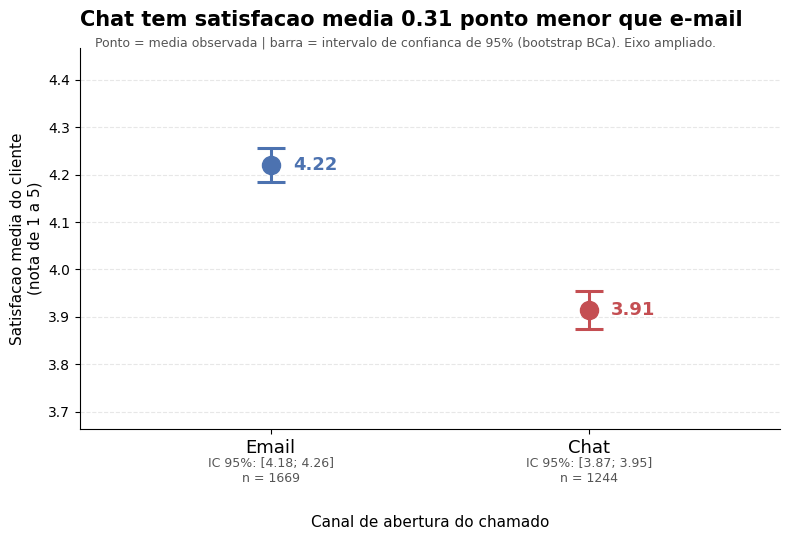

Limites do eixo y: (np.float64(3.663), np.float64(4.467))


In [20]:
canais = ["email", "chat"]
cores = {"email": "#4C72B0", "chat": "#C44E52"}

# --- Estatisticas: media e IC 95% bootstrap por canal ---------------------------
rng = np.random.default_rng(42)
stats_canal = {}

for canal in canais:
    x = df_consolidado_v2.loc[
        (df_consolidado_v2["canal"] == canal) & df_consolidado_v2["satisfacao_cliente"].notna(),
        "satisfacao_cliente",
    ].to_numpy(dtype=float)

    res = stats.bootstrap(
        (x,), statistic=np.mean, confidence_level=0.95,
        n_resamples=10000, method="BCa", random_state=rng,
    )
    stats_canal[canal] = {
        "n": x.size, "media": x.mean(),
        "low": res.confidence_interval.low,
        "high": res.confidence_interval.high,
    }

dif = stats_canal["email"]["media"] - stats_canal["chat"]["media"]

# --- Figura ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5.5))
pos = np.arange(len(canais))

for i, canal in enumerate(canais):
    s = stats_canal[canal]
    yerr = [[s["media"] - s["low"]], [s["high"] - s["media"]]]
    ax.errorbar(i, s["media"], yerr=yerr, fmt="o", markersize=13,
                color=cores[canal], capsize=10, capthick=2.2, elinewidth=2.2, zorder=3)
    ax.annotate(f"{s['media']:.2f}", xy=(i, s["media"]), xytext=(16, 0),
                textcoords="offset points", va="center", fontsize=13,
                fontweight="bold", color=cores[canal])
    ax.annotate(f"IC 95%: [{s['low']:.2f}; {s['high']:.2f}]\nn = {s['n']}",
                xy=(i, 0), xycoords=("data", "axes fraction"),
                xytext=(0, -38), textcoords="offset points",
                ha="center", fontsize=9, color="#555555")

# --- Eixos e escala -------------------------------------------------------------
todos = [v for s in stats_canal.values() for v in (s["low"], s["high"])]
folga = max((max(todos) - min(todos)) * 0.55, 0.10)
ax.set_ylim(min(todos) - folga, max(todos) + folga)

ax.set_xlim(-0.6, len(canais) - 0.4)
ax.set_xticks(pos)
ax.set_xticklabels([c.capitalize() for c in canais], fontsize=13)
ax.yaxis.set_major_locator(MultipleLocator(0.1))
ax.set_xlabel("Canal de abertura do chamado", fontsize=11, labelpad=42)
ax.set_ylabel("Satisfacao media do cliente\n(nota de 1 a 5)", fontsize=11)

ax.set_title(f"Chat tem satisfacao media {abs(dif):.2f} ponto menor que e-mail",
             fontsize=15, fontweight="bold", pad=16, loc="left")
fig.text(0.125, 0.90,
         "Ponto = media observada | barra = intervalo de confianca de 95% (bootstrap BCa). "
         "Eixo ampliado.",
         fontsize=9, color="#555555", ha="left", va="bottom")

ax.grid(axis="y", alpha=0.3, linestyle="--", zorder=0)
ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()

print("Limites do eixo y:", tuple(round(v, 3) for v in ax.get_ylim()))

### 7.2 Execute o código gerado e avalie criticamente as escolhas feitas pela IA: o tipo de gráfico é adequado, o eixo começa em zero ou foi recortado, e a agregação usada esconde variabilidade relevante?

In [21]:
# Evidências numéricas para a avaliação critica do gráfico
com_nota = df_consolidado_v2.dropna(subset=["satisfacao_cliente"])

faixa_eixo = 4.466896 - 3.663338   # limites impressos pela célula anterior
print("Faixa do eixo y usada pelo gráfico:", round(faixa_eixo, 3), "ponto")
print("Faixa da escala real da nota: 4.0 ponto (de 1 a 5)")
print(f"Proporção da escala real exibida: {faixa_eixo / 4 * 100:.1f}%")
print(f"\nA diferenca de {dif:.3f} ocupa {dif / faixa_eixo * 100:.1f}% da altura do painel,")
print(f"contra {dif / 4 * 100:.1f}% se o eixo cobrisse a escala inteira.\n")

resumo_canais = com_nota.groupby("canal").agg(
    n=("satisfacao_cliente", "size"),
    media=("satisfacao_cliente", "mean"),
    desvio_padrao=("satisfacao_cliente", "std"),
    tempo_resposta_medio=("tempo_resposta_horas", "mean"),
).round(3)
resumo_canais["erro_padrao"] = (resumo_canais["desvio_padrao"] / np.sqrt(resumo_canais["n"])).round(4)
resumo_canais["razao_dp_sobre_ep"] = (resumo_canais["desvio_padrao"] / resumo_canais["erro_padrao"]).round(1)
print("Dispersão das notas vs precisão da média, por canal:")
print(resumo_canais.to_string())

print("\nDistribuição das notas dentro de cada canal (proporção):")
print((com_nota.pivot_table(index="satisfacao_cliente", columns="canal", values="ticket_id", aggfunc="size").pipe(lambda t: t / t.sum())).round(3).to_string())

Faixa do eixo y usada pelo gráfico: 0.804 ponto
Faixa da escala real da nota: 4.0 ponto (de 1 a 5)
Proporção da escala real exibida: 20.1%

A diferenca de 0.307 ocupa 38.2% da altura do painel,
contra 7.7% se o eixo cobrisse a escala inteira.

Dispersão das notas vs precisão da média, por canal:
             n  media  desvio_padrao  tempo_resposta_medio  erro_padrao  razao_dp_sobre_ep
canal                                                                                     
chat      1244  3.914          0.719                 2.708       0.0204               35.2
email     1669  4.221          0.758                 4.367       0.0186               40.8
telefone   687  4.179          0.765                 4.555       0.0292               26.2

Distribuição das notas dentro de cada canal (proporção):
canal                chat  email  telefone
satisfacao_cliente                        
1.0                 0.002  0.002     0.001
2.0                 0.015  0.013     0.025
3.0               

**Avaliação crítica do gráfico gerado**

**Tipo de gráfico:** está adequado, e a justificativa da IA está correta, ponto com barra de erro é a escolha certa para comparar dois grupos com incerteza. Barra teria forçado o eixo a começar em zero e a diferença de 0,31 ponto desapareceria numa escala de 0 a 5.

**Eixo:** eixo recortado, e o recorte é agressivo, o `ylim` calculado ficou em [3,663; 4,467], ou seja, 0,80 ponto de uma escala que vai de 1 a 5, apenas 20% da escala real. A diferença ocupa cerca de 38% da altura do painel, contra 7,7% se o eixo cobrisse a escala inteira. A IA avisou do recorte, mas o aviso está em texto cinza de 9pt ao lado de um título em negrito de 15pt que afirma a diferença.

A agregação esconde variabilidade relevante, e este é o problema mais sério. A barra de erro é o intervalo de confiança da média, com margem de 0,04, e não a dispersão das notas, cujo desvio padrão é de 0,72 no chat e 0,76 no e-mail, cerca de 35 a 40 vezes maior que o erro-padrão. O gráfico dá a impressão de que os tickets de chat se concentram em torno de 3,91, quando as duas distribuições se sobrepõem quase inteiramente, o P(email > chat) é de 0,615, pouco acima de cara ou coroa.

**Omissão que a IA não avaliou:** O gráfico exclui o telefone, que tem média 4,179 e fica praticamente colado no e-mail. Mostrando só dois canais, a liderança lê o achado como e-mail contra chat. Com os três, fica evidente que o chat é o ponto fora da curva, e que ele é assim apesar de responder em 2,7 horas contra 4,4 e 4,6 dos outros dois.

### 7.3 Corrija o gráfico onde a avaliação identificou um problema, e escreva um título e uma legenda que comuniquem o achado de forma precisa ao time de suporte, sem exagerar a diferença real entre os canais.

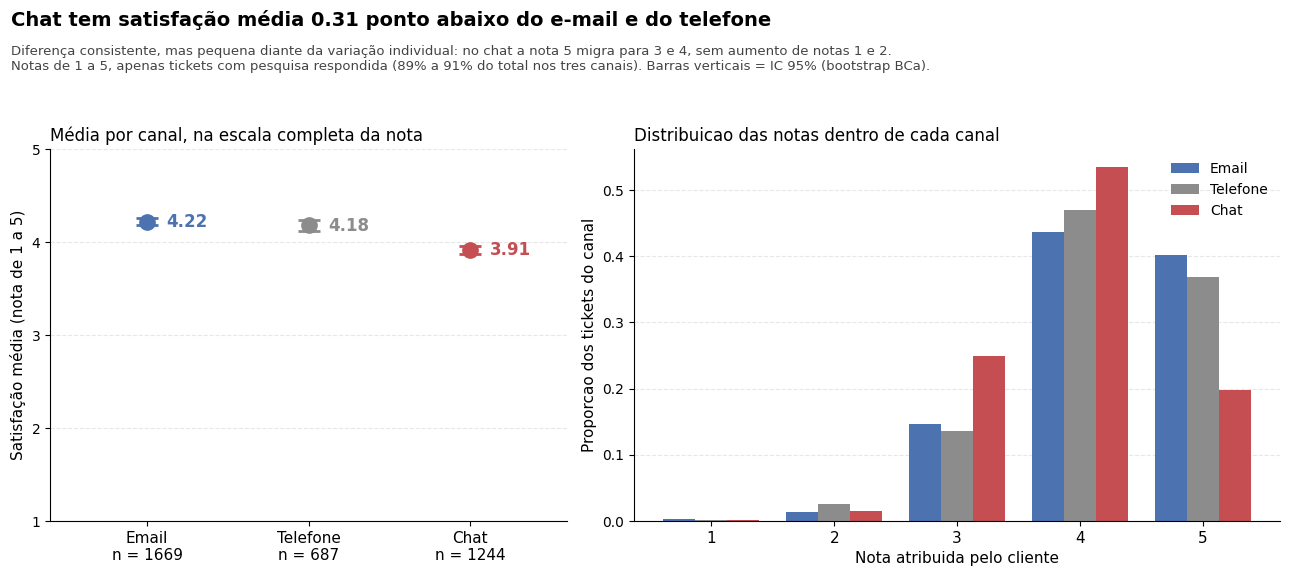

In [22]:
canais = ["email", "telefone", "chat"]
cor = {"email": "#4C72B0", "telefone": "#8C8C8C", "chat": "#C44E52"}
rng = np.random.default_rng(42)

resumo = {}
for canal in canais:
    x = df_consolidado_v2.loc[(df_consolidado_v2["canal"] == canal) & df_consolidado_v2["satisfacao_cliente"].notna(),
        "satisfacao_cliente"].to_numpy(dtype=float)
    r = stats.bootstrap((x,), statistic=np.mean, confidence_level=0.95,
                        n_resamples=10000, method="BCa", random_state=rng)
    resumo[canal] = {"n": x.size, "media": x.mean(), "dp": x.std(ddof=1),
                     "low": r.confidence_interval.low, "high": r.confidence_interval.high,
                     "dist": pd.Series(x).value_counts(normalize=True).sort_index()}

dif = resumo["email"]["media"] - resumo["chat"]["media"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [1, 1.25]})

# Painel 1: média e IC 95% na escala completa da nota
# Correção 1: eixo de 1 a 5, sem recorte, para não exagerar a diferença
# Correção 2: telefone incluido, para mostrar que o chat e o ponto fora da curva
for i, canal in enumerate(canais):
    s = resumo[canal]
    ax1.errorbar(i, s["media"], yerr=[[s["media"] - s["low"]], [s["high"] - s["media"]]],
                 fmt="o", markersize=11, color=cor[canal],
                 capsize=8, capthick=2, elinewidth=2, zorder=3)
    ax1.annotate(f"{s['media']:.2f}", xy=(i, s["media"]), xytext=(14, 0),
                 textcoords="offset points", va="center", fontsize=12,
                 fontweight="bold", color=cor[canal])
ax1.set_ylim(1, 5)
ax1.set_yticks([1, 2, 3, 4, 5])
ax1.set_xlim(-0.6, len(canais) - 0.4)
ax1.set_xticks(range(len(canais)))
ax1.set_xticklabels([f"{c.capitalize()}\nn = {resumo[c]['n']}" for c in canais], fontsize=11)
ax1.set_ylabel("Satisfação média (nota de 1 a 5)", fontsize=11)
ax1.set_title("Média por canal, na escala completa da nota", fontsize=12, loc="left")
ax1.grid(axis="y", alpha=0.3, linestyle="--", zorder=0)
ax1.set_axisbelow(True)

for lado in ["top", "right"]:
    ax1.spines[lado].set_visible(False)

# Painel 2: distribuição das notas dentro de cada canal
# Correção 3: devolve a variabilidade que a média sozinha escondia
notas = [1, 2, 3, 4, 5]
largura = 0.26
for i, canal in enumerate(canais):
    props = [resumo[canal]["dist"].get(float(nota), 0.0) for nota in notas]
    ax2.bar(np.arange(len(notas)) + (i - 1) * largura, props, width=largura, color=cor[canal], label=canal.capitalize())

ax2.set_xticks(range(len(notas)))
ax2.set_xticklabels(notas, fontsize=11)
ax2.set_xlabel("Nota atribuida pelo cliente", fontsize=11)
ax2.set_ylabel("Proporcao dos tickets do canal", fontsize=11)
ax2.set_title("Distribuicao das notas dentro de cada canal", fontsize=12, loc="left")
ax2.legend(frameon=False, fontsize=10)
ax2.grid(axis="y", alpha=0.3, linestyle="--", zorder=0)
ax2.set_axisbelow(True)

for lado in ["top", "right"]:
    ax2.spines[lado].set_visible(False)

fig.suptitle(f"Chat tem satisfação média {abs(dif):.2f} ponto abaixo do e-mail e do telefone", fontsize=14, fontweight="bold", x=0.012, ha="left", y=0.985)
fig.text(0.012, 0.925,
         "Diferença consistente, mas pequena diante da variação individual: no chat a nota 5 "
         "migra para 3 e 4, sem aumento de notas 1 e 2.\n"
         "Notas de 1 a 5, apenas tickets com pesquisa respondida (89% a 91% do total nos tres "
         "canais). Barras verticais = IC 95% (bootstrap BCa).",
         fontsize=9.5, color="#444444", ha="left", va="top")

plt.tight_layout(rect=[0, 0, 1, 0.87])
plt.show()

**Título, legenda e correções aplicadas**

**Título:** Chat tem satisfação média 0,31 ponto abaixo do e-mail e do telefone.

**Legenda:** Diferença consistente, mas pequena diante da variação individual: no chat a nota 5 migra para 3 e 4, sem aumento de notas 1 e 2. Notas de 1 a 5, apenas tickets com pesquisa respondida (89% a 91% do total nos três canais). Barras verticais representam o intervalo de confiança de 95% da média, por bootstrap BCa.

Três correções foram aplicadas. O eixo do painel da esquerda passou a cobrir a escala completa de 1 a 5, o que elimina a necessidade do aviso de recorte. O telefone entrou na comparação, o que reposiciona o achado, o chat não perde para o e-mail, ele perde para os outros dois canais, que ficam praticamente empatados. E o painel da direita devolve a variabilidade que a média escondia.

O painel da direita também produziu um achado que nenhuma das respostas da LLM tinha alcançado, a diferença não vem de reclamação. As notas 1 e 2 somam 1,7% no chat e 1,5% no e-mail, e o que muda é o topo, com 39,9% de notas 5 no e-mail contra 19,9% no chat. Isso altera a recomendação operacional, porque o problema não é de clientes revoltados e sim de um teto de excelência mais baixo.

##**EXERCÍCIO 8**

### 8.1 Use um LLM para gerar e revisar o código de limpeza do recorte de tickets de categoria "bug" nos 30 dias mais recentes do período coberto pela base.

**PROMPT ENVIADO À LLM**

```
Tenho um DataFrame pandas chamado df_consolidado_v2 com tickets de suporte da CloudDesk. Colunas relevantes: ticket_id, data_abertura (datetime), canal, categoria (bug, duvida_de_uso, cobranca, elogio), prioridade, tempo_resposta_horas, tempo_resolucao_horas, satisfacao_cliente, segmento.

Preciso de código pandas que isole um recorte da base: apenas os tickets de categoria "bug" abertos nos 30 dias mais recentes do período coberto pela base (ou seja, os 30 dias que antecedem a data de abertura máxima presente nos dados, não a data de hoje).

O código deve, além do filtro, verificar o recorte resultante: número de linhas, data mínima e máxima, contagem de valores ausentes por coluna e duplicatas em ticket_id.
Gere apenas o código, sem executar e sem inventar as saídas.
```

**RESPOSTA DA LLM**

> Uma decisão que vale explicitar: uso janela fechada nas duas pontas — `data_max - 29 dias` até `data_max`, inclusive. Isso dá exatamente 30 dias-calendário. A alternativa (`> data_max - 30 dias`) dá o mesmo conjunto em dados só-data, mas se `data_abertura` tiver componente de hora as duas divergem. Deixei o corte explícito e normalizado para o comportamento não depender disso.
>
> *[código gerado - colado na célula abaixo]*
>
> Dois pontos sobre o que a verificação pode revelar.
>
> O contador de "dias distintos com ticket" existe para pegar buracos na janela. Se vierem 22 de 30, há dias sem chamado nenhum — pode ser fim de semana, pode ser falha de exportação, e a distinção muda o que você conclui do recorte.
>
> Sobre o tamanho: `bug` é cerca de 35% da base, e 30 dias são um sexto do período coberto. O recorte deve ficar na casa das duas centenas de linhas. É suficiente para descritivas, mas fica apertado se você quiser cruzar por canal e prioridade ao mesmo tempo — algumas células vão ter dígito único. Vale conferir os n antes de tirar conclusões de qualquer subgrupo.

**CÓDIGO GERADO PELA LLM**

In [23]:
df = df_consolidado_v2.copy()

# --- 0) Garantia de tipo --------------------------------------------------------
df["data_abertura"] = pd.to_datetime(df["data_abertura"])

# --- 1) Definicao da janela, ancorada no dado (nao em pd.Timestamp.today()) -----
data_max = df["data_abertura"].max().normalize()
data_corte = data_max - pd.Timedelta(days=29)   # 29, nao 30: janela inclusiva
                                                # dos dois lados = 30 dias-calendario

print(f"Data maxima na base: {data_max:%Y-%m-%d}")
print(f"Janela considerada:  {data_corte:%Y-%m-%d} a {data_max:%Y-%m-%d} "
      f"({(data_max - data_corte).days + 1} dias)\n")

# --- 2) Recorte: categoria bug E dentro da janela -------------------------------
mask_bug = df["categoria"] == "bug"
mask_janela = df["data_abertura"].between(data_corte, data_max, inclusive="both")

df_bug_30d = df.loc[mask_bug & mask_janela].copy()

print(f"Base completa:              {len(df):>6d} linhas")
print(f"Apos filtro categoria=bug:  {mask_bug.sum():>6d} linhas")
print(f"Apos filtro janela 30d:     {len(df_bug_30d):>6d} linhas\n")

# --- 3) Verificacao do recorte --------------------------------------------------
print("=" * 60)
print("VERIFICACAO DO RECORTE")
print("=" * 60)

if df_bug_30d.empty:
    print("ATENCAO: o recorte esta vazio. Verifique os filtros.")
else:
    print(f"Linhas:        {len(df_bug_30d)}")
    print(f"Data minima:   {df_bug_30d['data_abertura'].min():%Y-%m-%d}")
    print(f"Data maxima:   {df_bug_30d['data_abertura'].max():%Y-%m-%d}")
    print(f"Dias distintos com ticket: {df_bug_30d['data_abertura'].dt.date.nunique()} de 30")

    n_dup = df_bug_30d["ticket_id"].duplicated().sum()
    print(f"\nDuplicatas em ticket_id: {n_dup}")

    ausentes = pd.DataFrame({
        "n_ausentes": df_bug_30d.isna().sum(),
        "pct_ausentes": (df_bug_30d.isna().mean() * 100).round(2),
    })
    print("\nValores ausentes por coluna:")
    print(ausentes.to_string())

    print(f"\nCategorias presentes no recorte: "
          f"{df_bug_30d['categoria'].unique().tolist()}")

Data maxima na base: 2026-07-03
Janela considerada:  2026-06-04 a 2026-07-03 (30 dias)

Base completa:                4000 linhas
Apos filtro categoria=bug:    1387 linhas
Apos filtro janela 30d:        230 linhas

VERIFICACAO DO RECORTE
Linhas:        230
Data minima:   2026-06-04
Data maxima:   2026-07-03
Dias distintos com ticket: 30 de 30

Duplicatas em ticket_id: 0

Valores ausentes por coluna:
                       n_ausentes  pct_ausentes
ticket_id                       0          0.00
cliente_id                      0          0.00
data_abertura                   0          0.00
canal                           0          0.00
categoria                       0          0.00
prioridade                      0          0.00
tempo_resposta_horas            0          0.00
tempo_resolucao_horas           0          0.00
satisfacao_cliente             19          8.26
valor_plano                     0          0.00
segmento                        0          0.00
intencao_triagem     

**Revisão do código gerado**

O recorte vai de 2026-06-04 a 2026-07-03 e tem 230 linhas, partindo de 1387 tickets de categoria `bug` na base completa. A previsão do modelo sobre o tamanho ("casa das duas centenas") se confirmou. Não há duplicatas em `ticket_id`, e os 30 dias da janela têm todos pelo menos um chamado, o que descarta buracos de exportação.

Um ponto exige revisão humana e o código não sinaliza, os 68,70% de ausentes em `intencao_triagem` e `confianca_bot` são estruturais, não sujeira. Essas duas colunas vêm do JSON de triagem, que só cobre o canal chat, e o chat responde por 72 dos 230 tickets do recorte, ou 31,3%, o complemento exato dos 68,70%. Tratar isso como dado faltante e tentar imputar seria um erro grave. Os únicos ausentes reais são os 19 tickets sem `satisfacao_cliente` (8,26%).

A decisão do modelo de ancorar a janela na data máxima presente nos dados, e não em `pd.Timestamp.today()`, está correta, a base termina em 2026-07-03, e usar a data corrente devolveria um recorte vazio.

### 8.2 Formule, com apoio de IA, uma pergunta analítica relevante sobre esse recorte que envolva comparar uma métrica numérica entre dois subgrupos, e obtenha a resposta com código gerado por LLM.

**Pergunta formulada**

A política de priorização está funcionando, ou seja, bugs de prioridade alta ou crítica são resolvidos mais rápido que bugs de prioridade baixa ou média?

A escolha se justifica por três motivos, a métrica comparada é numérica e contínua (`tempo_resolucao_horas`), os dois subgrupos têm tamanho suficiente para bootstrap (88 e 142 tickets), e a pergunta tem consequência operacional direta, porque se a fila de prioridade não acelera a resolução, ela não está cumprindo a função para a qual existe.

**PROMPT ENVIADO À LLM**

```
Tenho um DataFrame pandas chamado df_bug_30d, um recorte de 230 tickets de categoria "bug" abertos nos 30 dias mais recentes da base de suporte da CloudDesk (2026-06-04 a 2026-07-03). Colunas: ticket_id, cliente_id, data_abertura, canal, categoria, prioridade (baixa/media/alta/critica), tempo_resposta_horas, tempo_resolucao_horas, satisfacao_cliente, valor_plano, segmento.

Quero responder: a política de priorização está funcionando, ou seja, bugs de prioridade alta ou crítica são resolvidos mais rápido que bugs de prioridade baixa ou média? Gere o código pandas que compara o tempo_resolucao_horas médio entre esses dois subgrupos, com o n de cada um. Apenas código, sem inventar as saídas.
```

**RESPOSTA DA LLM**

> *[código gerado - colado na célula abaixo]*
>
> Dois pontos que valem atenção antes de você interpretar o resultado.
>
> O primeiro é a censura: se `tempo_resolucao_horas` vem vazio para tickets ainda abertos, a média só enxerga os que já fecharam. Bugs críticos difíceis que continuam abertos ficam de fora e puxam a média do grupo urgente para baixo artificialmente. Por isso o resumo separa `n_resolvidos` de `n_sem_resolucao` — se essa coluna estiver desbalanceada entre os grupos, a comparação de médias não sustenta a conclusão sozinha.
>
> O segundo é que tempo de resolução costuma ter cauda longa à direita, então a média fica sensível a uns poucos tickets muito demorados. A mediana e o intervalo p25–p75 no mesmo output servem para você checar se os dois indicadores contam a mesma história. Se média e mediana divergirem bastante, a mediana é a leitura mais confiável.
>
> Um detalhe do recorte em si: 230 tickets de uma categoria em 30 dias é uma amostra pequena quando dividida em dois grupos, e ainda mais se os urgentes forem minoria. Se você quiser testar se a diferença observada é distinguível de ruído, um Mann-Whitney (`scipy.stats.mannwhitneyu`) é mais adequado que um teste t aqui, justamente pela assimetria da distribuição.

**CÓDIGO GERADO PELA LLM**

In [24]:
# 0) Sanidade: confere se so existem os 4 rotulos esperados de prioridade.
#    Qualquer valor inesperado (typo, maiuscula, NaN) cairia silenciosamente
#    no grupo "baixa/media" com o isin abaixo.
print(df_bug_30d["prioridade"].value_counts(dropna=False))

# 1) Define os dois subgrupos
eh_urgente = df_bug_30d["prioridade"].isin(["alta", "critica"])
df_grupos = df_bug_30d.assign(
    grupo=eh_urgente.map({True: "alta/critica", False: "baixa/media"})
)

# 2) Compara tempo de resolucao entre os grupos
resumo_prioridade = (
    df_grupos.groupby("grupo")["tempo_resolucao_horas"]
    .agg(
        n_total="size",           # tickets no grupo
        n_resolvidos="count",     # count ignora NaN -> base real da media
        media="mean",
        mediana="median",
        desvio="std",
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
    )
    .round(2)
)
resumo_prioridade["n_sem_resolucao"] = (
    resumo_prioridade["n_total"] - resumo_prioridade["n_resolvidos"]
)

print()
print(resumo_prioridade.to_string())

# 3) Diferenca entre as medias (positivo = urgentes demoram mais)
dif_prioridade = (resumo_prioridade.loc["alta/critica", "media"]
                  - resumo_prioridade.loc["baixa/media", "media"])
print(f"\nDiferenca de medias (alta/critica - baixa/media): {dif_prioridade:.2f} h")

prioridade
baixa      71
media      71
alta       61
critica    27
Name: count, dtype: int64

              n_total  n_resolvidos  media  mediana  desvio   p25    p75  n_sem_resolucao
grupo                                                                                    
alta/critica       88            88   8.69     7.71    4.68  5.43  11.22                0
baixa/media       142           142   9.53     8.53    5.00  6.58  11.88                0

Diferenca de medias (alta/critica - baixa/media): -0.84 h


**MINHA ANÁLISE**

Os bugs de prioridade alta ou crítica são resolvidos em 8,69 horas em média contra 9,53 dos de prioridade baixa ou média, uma diferença de 0,84 hora a favor dos urgentes.

As duas verificações que o modelo pediu se confirmam favoráveis. A censura que ele levantou não existe neste recorte: `n_sem_resolucao` é zero nos dois grupos. E média e mediana contam a mesma história (8,69 contra 7,71 no grupo urgente, 9,53 contra 8,53 no outro), com desvios de 4,68 e 5,00 sobre médias de aproximadamente 9. A cauda longa que ele temia está em `tempo_resposta_horas`, não aqui, então a recomendação de Mann-Whitney pela assimetria não se justifica neste caso.

### 8.3 Peça ao LLM que estruture essa comparação; se ele sugerir um teste de hipótese clássico com p-valor, redirecione a análise para intervalos de confiança via scipy.stats.bootstrap, e peça ao LLM que explique o resultado. Valide essa explicação por escrito antes de aceitá-la.

**PROMPT ENVIADO Á LLM**

```
Prefiro raciocinar em termos de intervalos de confiança em vez de p-valor. Gere o código que calcula, com scipy.stats.bootstrap, o IC 95% do tempo_resolucao_horas médio de cada um dos dois subgrupos e o IC 95% da diferença entre eles. Depois de gerar o código, explique como eu devo interpretar o resultado caso o intervalo da diferença contenha o zero.
```

**RESPOSTA DA LLM**

> *[código gerado - colado na célula abaixo]*
>
> Uma observação sobre os ICs individuais: não use a sobreposição entre eles para decidir sobre a diferença. Dois intervalos podem se sobrepor e ainda assim o IC da diferença excluir o zero. O intervalo da diferença é o que responde à sua pergunta; os individuais servem para você ver a magnitude absoluta de cada grupo.
>
> **Se o intervalo da diferença contiver o zero**
>
> A leitura correta é que os dados são compatíveis com a ausência de diferença — não que a diferença seja zero. Essa distinção não é preciosismo: o intervalo contém o zero, mas contém também todos os outros valores dentro dos seus limites, e eles têm o mesmo direito à sua atenção.
>
> O que fazer, então, é olhar para os extremos do intervalo e perguntar se eles descrevem cenários operacionalmente diferentes. Suponha que dê [-14, +9]. O limite inferior significa que os bugs urgentes podem estar sendo resolvidos 14 horas mais rápido — uma política funcionando bem. O superior significa que podem estar demorando 9 horas a mais — uma política invertida. Se esses dois cenários levariam você a decisões diferentes, o resultado é inconclusivo: a amostra não é grande o suficiente para distinguir entre eles, e a conclusão honesta é "ainda não sei", não "a política não faz diferença".
>
> O caso oposto é um intervalo estreito em torno do zero, tipo [-1.5, +2]. Aí você tem informação de verdade: seja qual for o efeito real, ele é pequeno demais para importar na prática. Isso sim é evidência de que a priorização não está produzindo diferença operacional relevante — e é uma conclusão bem mais forte que a anterior, apesar de ambas "conterem o zero".
>
> Vale definir qual diferença seria relevante para a CloudDesk antes de olhar o número. Se a meta interna é que crítico resolva em metade do tempo, o critério é grande; se qualquer ganho de 2 horas já justifica manter a política, é pequeno. Sem esse parâmetro definido previamente, fica fácil racionalizar qualquer intervalo depois do fato.
>
> Dois pontos do recorte que limitam a conclusão em qualquer cenário. O primeiro é a censura que mencionei antes — o `dropna()` no início do código remove tickets ainda abertos, e se os urgentes estiverem sobrerrepresentados entre os não resolvidos, o IC está estimando o tempo médio dos casos que fecharam, que é outra coisa.
>
> O segundo é confundimento por severidade: bugs marcados como críticos podem ser genuinamente mais difíceis, então uma diferença próxima de zero pode significar que a priorização está funcionando e apenas compensando a dificuldade extra. Esse recorte observacional de 30 dias não separa as duas explicações.

**CÓDIGO GERADO PELA LLM**

In [25]:
# 1) Separa os dois subgrupos, ja descartando tickets sem tempo de resolucao.
#    O bootstrap nao lida com NaN: um unico NaN contamina toda a reamostragem.
eh_urgente = df_bug_30d["prioridade"].isin(["alta", "critica"])

x_urg = df_bug_30d.loc[eh_urgente, "tempo_resolucao_horas"].dropna().to_numpy()
x_bm = df_bug_30d.loc[~eh_urgente, "tempo_resolucao_horas"].dropna().to_numpy()

print(f"n alta/critica (resolvidos): {len(x_urg)}")
print(f"n baixa/media  (resolvidos): {len(x_bm)}")

rng = np.random.default_rng(42)

# 2) IC 95% da media de cada grupo (BCa corrige assimetria e vies)
ic_urg = bootstrap((x_urg,), np.mean, confidence_level=0.95,
                   n_resamples=10000, method="BCa", random_state=rng)
ic_bm = bootstrap((x_bm,), np.mean, confidence_level=0.95,
                  n_resamples=10000, method="BCa", random_state=rng)

# 3) IC 95% da diferenca de medias (urgentes - nao urgentes)
def dif_medias_bug(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)

ic_dif = bootstrap((x_urg, x_bm), dif_medias_bug, confidence_level=0.95,
                   n_resamples=10000, method="BCa", random_state=rng)

# 4) Saida
dif_pontual = x_urg.mean() - x_bm.mean()

print(f"\nalta/critica : media {x_urg.mean():.2f} h  "
      f"IC95% [{ic_urg.confidence_interval.low:.2f}, {ic_urg.confidence_interval.high:.2f}]")
print(f"baixa/media  : media {x_bm.mean():.2f} h  "
      f"IC95% [{ic_bm.confidence_interval.low:.2f}, {ic_bm.confidence_interval.high:.2f}]")
print(f"\ndiferenca (alta/critica - baixa/media): {dif_pontual:.2f} h  "
      f"IC95% [{ic_dif.confidence_interval.low:.2f}, {ic_dif.confidence_interval.high:.2f}]")
print(f"erro-padrao bootstrap da diferenca: {ic_dif.standard_error:.2f} h")

n alta/critica (resolvidos): 88
n baixa/media  (resolvidos): 142

alta/critica : media 8.69 h  IC95% [7.81, 9.75]
baixa/media  : media 9.53 h  IC95% [8.77, 10.41]

diferenca (alta/critica - baixa/media): -0.84 h  IC95% [-2.18, 0.41]
erro-padrao bootstrap da diferenca: 0.66 h


**Validação da explicação**

A explicação está correta e é aplicável ao resultado obtido.

A distinção entre "os dados são compatíveis com ausência de diferença" e "a diferença é zero" está certa e evita o erro mais comum na leitura de um intervalo que contém o zero. O alerta contra usar sobreposição dos ICs individuais é decisivo aqui: os dois intervalos individuais se sobrepõem ([7,81; 9,75] e [8,77; 10,41]) e o da diferença também contém o zero, então as duas leituras coincidem, mas coincidem por acaso, e seria erro tratar a primeira como prova da segunda.

O critério que ele propõe para decidir entre "inconclusivo" e "efeito pequeno demais para importar" se aplica diretamente ao número obtido. O intervalo da diferença vai de -2,18 h a +0,41 h: o limite inferior significaria bugs urgentes resolvidos duas horas mais rápido, e o superior significaria praticamente nenhuma diferença. Esses dois cenários não levariam a CloudDesk a decisões operacionais diferentes, então este é o caso do intervalo estreito em torno do zero, e não o do resultado inconclusivo.

A ressalva sobre confundimento por severidade também procede e não tem solução com estes dados. Já a ressalva sobre censura não se aplica, porque nenhum ticket do recorte está sem tempo de resolução.

**Interpretação de negócio:** entre os 230 bugs dos últimos 30 dias, chamados de prioridade alta ou crítica são resolvidos 0,84 hora mais rápido que os de prioridade baixa ou média, mas o intervalo de confiança de 95% vai de -2,18 h a +0,41 h. Como as duas pontas do intervalo descrevem o mesmo cenário operacional, a leitura é que a política de priorização não está produzindo diferença relevante no tempo de resolução de bugs.

### 8.4 Feche com uma avaliação crítica de todo o processo: aponte um ponto em que a IA foi confiável e um ponto em que sua revisão humana foi indispensável.

**Avaliação crítica do processo**

**Onde a IA foi confiável:** na antecipação de problemas que os prompts não mencionavam.

O caso mais claro é o do Exercício 1. O prompt informava o nome das colunas e o critério de negócio, mas não dizia que `tempo_resposta_horas` viria como texto com vírgula decimal. O modelo detectou isso sozinho e explicou por que o `groupby(...).median()` falharia sem a conversão. Na mesma resposta, decidiu remover as duplicatas antes de calcular a mediana com uma justificativa mais defensável que a ordem adotada no TP1.

No Exercício 4 previu que a tabela cruzada teria células vazias por causa da correlação de 0,92 e já entregou a versão mascarada, o que se confirmou, apenas 12 das 25 células passaram do corte. Ainda no Exercício 4, insistiu que os quintis fossem calculados sobre a distribuição global e não dentro de cada canal. No Exercício 7 escolheu ponto com intervalo em vez de barra pelo motivo certo. E no Exercício 8.1 estimou o tamanho do recorte em "duas centenas de linhas" antes de qualquer execução, contra as 230 obtidas.

**Onde a revisão humana foi indispensável:** na identificação de erros silenciosos.

Nenhum código gerado levantou exceção. O erro do Exercício 1 só apareceu porque foi construído um subconjunto de teste com um valor sabidamente corrompido, o `errors="coerce"` transformou 5,19 horas em `NaN` e o `fillna` o substituiu por 1,87 hora, um erro de 64% sem aviso e sem rastro. E a divergência de 236 linhas em relação ao TP1 não apareceria em nenhuma inspeção de `shape`, `dtypes` ou contagem de nulos, que era justamente o que o código gerado imprimia como verificação.

A revisão humana também foi necessária no sentido oposto, o de não aceitar como problema aquilo que a IA alertou sem medir. O alerta mais enfático de todo o TP foi o de que os intervalos do Exercício 5 estariam até 45% estreitos demais pela dependência entre tickets do mesmo cliente. O mecanismo é real, mas o ICC calculado é de 0,001, com fator de inflação de 1,01. O modelo estimou a ordem de grandeza sem ter como calculá-la, e apresentou a estimativa com a mesma segurança com que apresentou o resto.

Os dois casos apontam para a mesma conclusão, o modelo é forte em levantar o que verificar e fraco em saber se aquilo importa nesta base. A verificação continua sendo trabalho de quem conhece o dataset.